
Protected feature matching report
Class distribution: Counter({0: 91277, 1: 25619})
Scale pos weight (XGB): 3.5629

STARTING HYPERPARAMETER TUNING + OOF THRESHOLD SELECTION (train set only)

Processing model: LR
Fitting 10 folds for each of 20 candidates, totalling 200 fits
  ✅ Best parameters:
     clf__C: 0.9846738873614566
     clf__max_iter: 2138
     clf__penalty: l2
     clf__solver: liblinear
     rf_select__threshold: 0.01
  Best inner CV AP-AUC: 0.4469
  Generating out-of-fold predictions (train set only)...
  OOF-derived threshold: 0.510  |  AP-AUC=0.446  ROC-AUC=0.780

Processing model: RF
Fitting 10 folds for each of 20 candidates, totalling 200 fits
  ✅ Best parameters:
     clf__max_depth: None
     clf__max_features: sqrt
     clf__min_samples_leaf: 8
     clf__min_samples_split: 9
     clf__n_estimators: 162
     rf_select__threshold: 0.01
  Best inner CV AP-AUC: 0.4887
  Generating out-of-fold predictions (train set only)...
  OOF-derived threshold: 0.510  |  AP-AUC=0

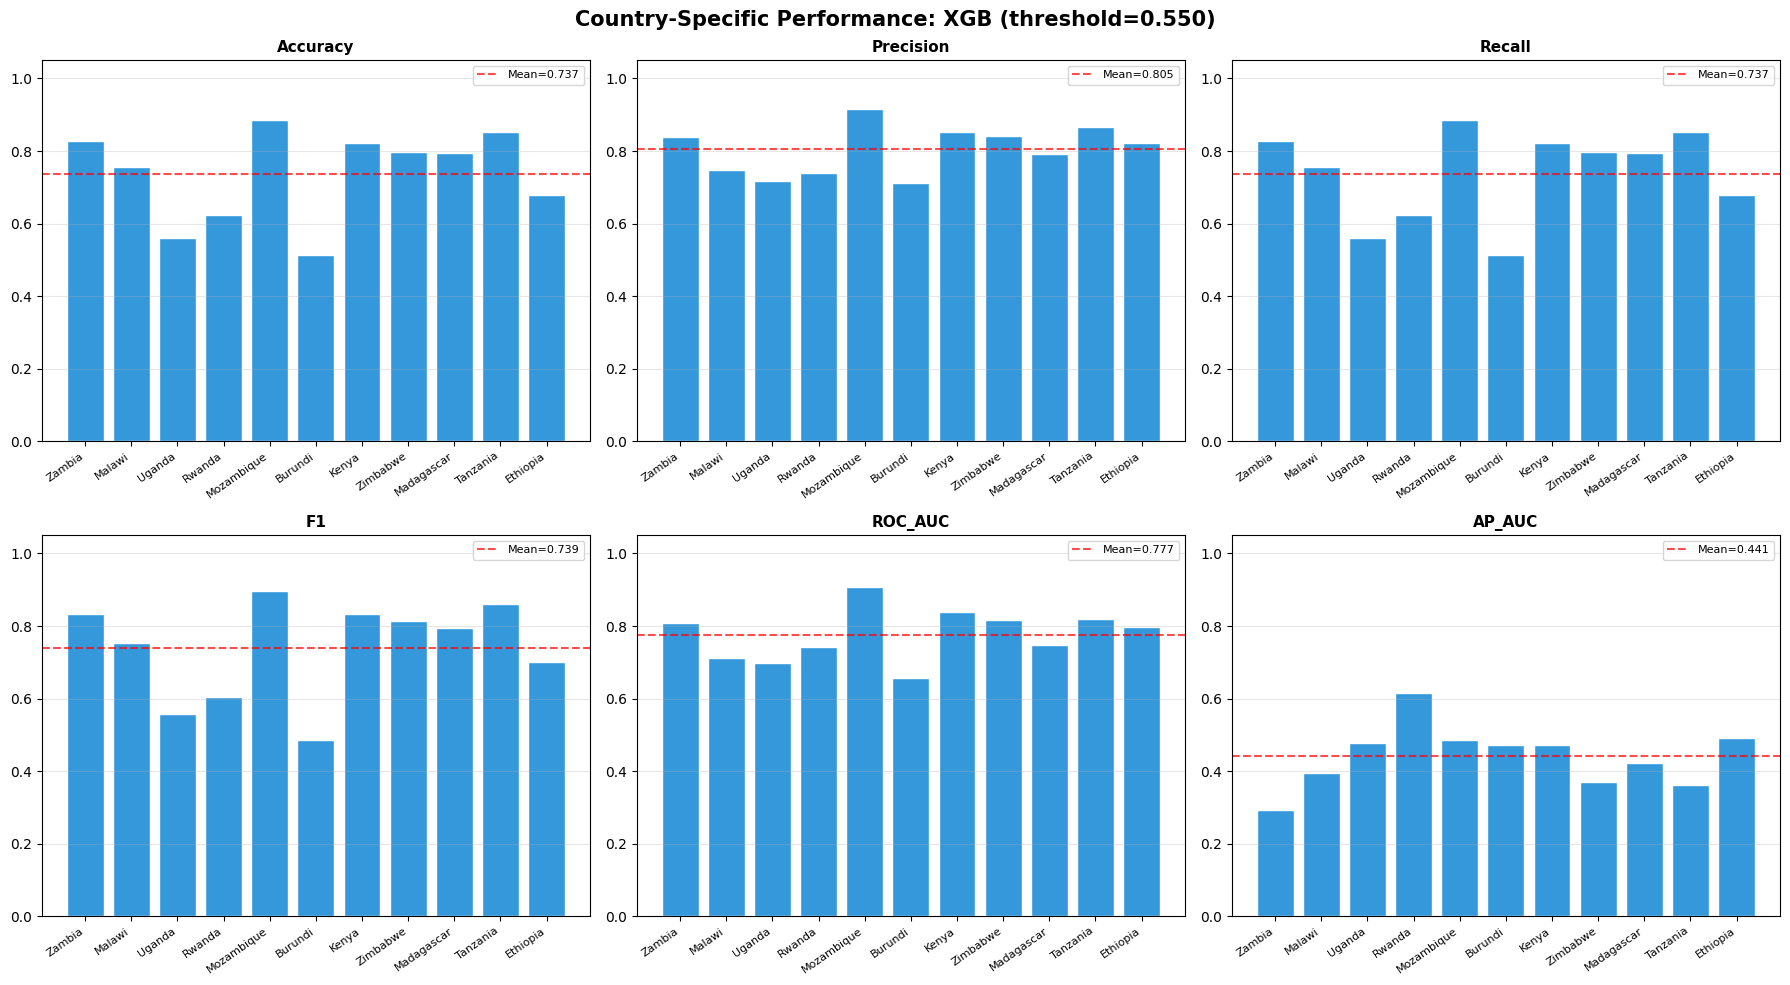

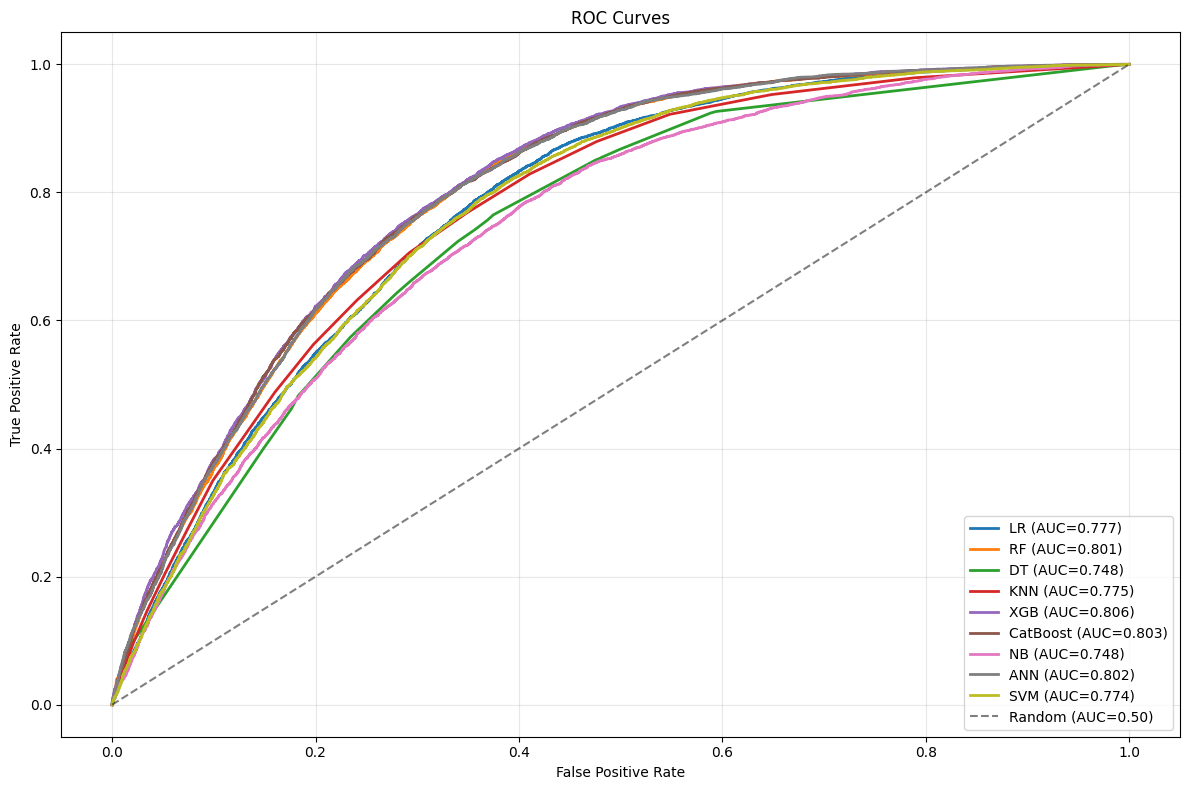

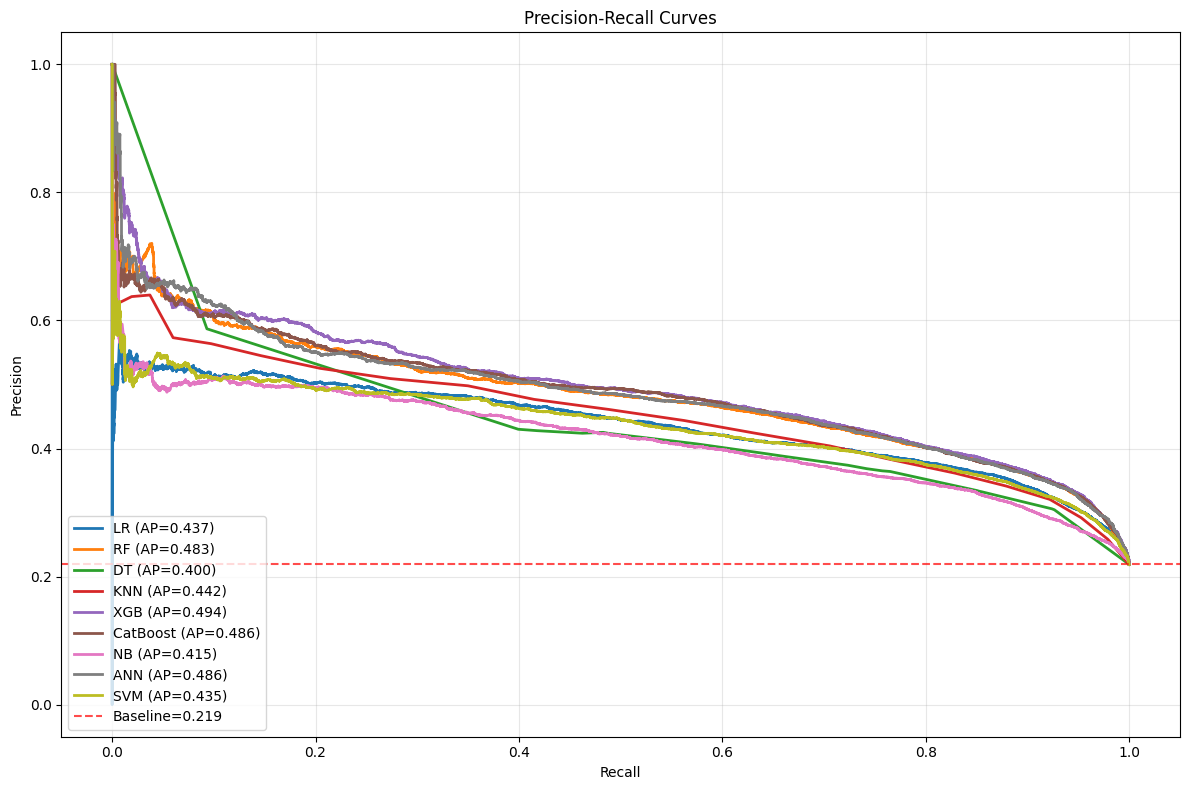

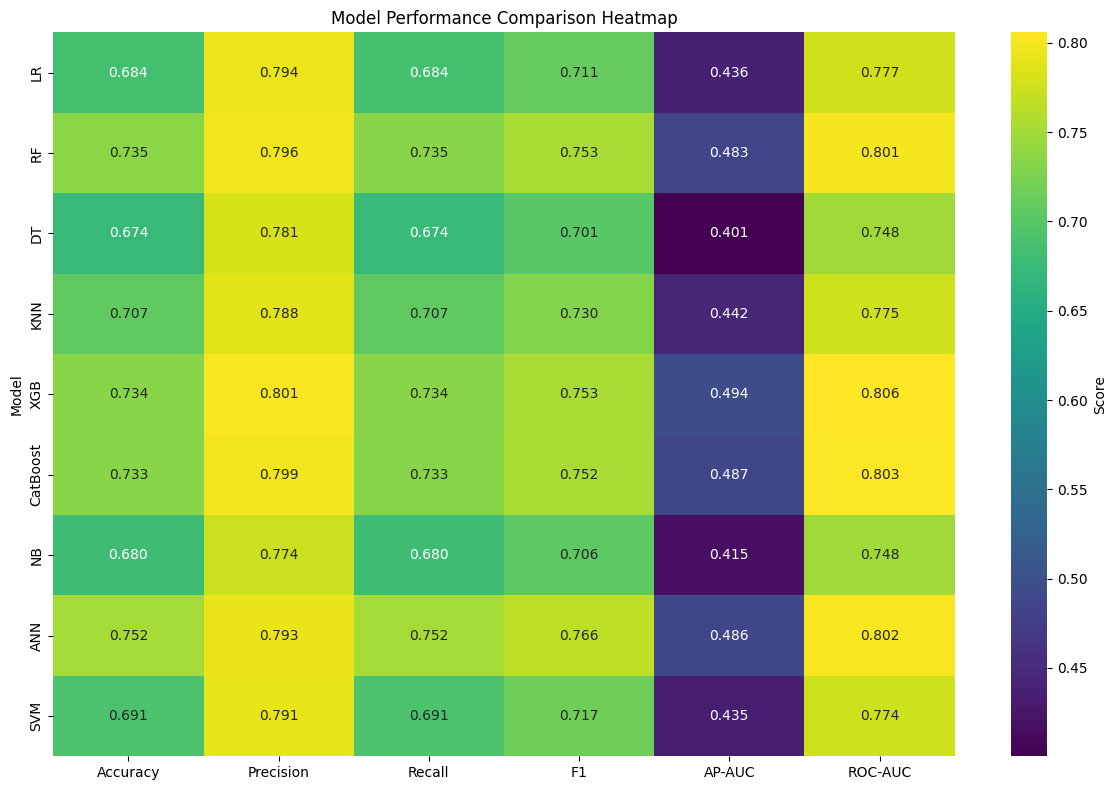


✅  BEST MODEL SAVED
  Model              : XGB
  Fixed threshold    : 0.550  (selected from train-set OOF predictions only)
  AP-AUC             : 0.4942 (0.4809-0.5072)
  ROC-AUC            : 0.8059 (0.8003-0.8115)
  Accuracy           : 0.7337 (0.7285-0.7387)
  Precision          : 0.8013 (0.7965-0.8060)
  Recall             : 0.7338 (0.7288-0.7387)
  F1-Score           : 0.7531 (0.7483-0.7577)

✅ All outputs saved to: C:\Users\wub\Desktop\ABC\ABC


In [1]:
#============================================================
import re
import difflib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.preprocessing._encoders")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.parallel")

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from scipy.stats import randint, uniform, loguniform
from statsmodels.stats.outliers_influence import variance_inflation_factor
import joblib
from collections import Counter

OUTPUT_PATH = r"C:\Users\wub\Desktop\ABC\ABC"

# ============================================================
# 1. CUSTOM TRANSFORMERS
# ============================================================

class CorrelationVIFSelector(BaseEstimator, TransformerMixin):
    """Removes correlated & high-VIF features"""
    def __init__(self, corr_threshold=0.7, vif_threshold=5, protect_indices=None):
        self.corr_threshold = corr_threshold
        self.vif_threshold = vif_threshold
        self.protect_indices = protect_indices if protect_indices is not None else []
        self.keep_indices_ = None

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        n_features = X.shape[1]
        if n_features <= 1:
            self.keep_indices_ = np.arange(n_features)
            return self

        protected = set(self.protect_indices)
        corr = np.corrcoef(X, rowvar=False)
        corr = np.nan_to_num(corr, nan=0.0)
        high_corr_pairs = []
        for i in range(n_features):
            for j in range(i + 1, n_features):
                if abs(corr[i, j]) > self.corr_threshold:
                    high_corr_pairs.append((i, j))
        mean_abs_corr = np.mean(np.abs(corr), axis=0)
        drop_set = set()
        for i, j in high_corr_pairs:
            if i in drop_set or j in drop_set:
                continue
            if i in protected and j in protected:
                continue  # never drop two protected features against each other
            if i in protected:
                drop_set.add(j)
            elif j in protected:
                drop_set.add(i)
            else:
                if mean_abs_corr[i] >= mean_abs_corr[j]:
                    drop_set.add(i)
                else:
                    drop_set.add(j)
        keep_indices = [i for i in range(n_features) if i not in drop_set]

        unprotected_remaining = [i for i in keep_indices if i not in protected]
        if len(unprotected_remaining) >= 2:
            X_rem = X[:, unprotected_remaining]
            stds = np.std(X_rem, axis=0)
            non_const = [idx for idx, s in enumerate(stds) if s > 1e-10]
            if len(non_const) >= 2:
                X_vif = X_rem[:, non_const]
                vif_data = np.zeros(len(non_const))
                for idx in range(len(non_const)):
                    try:
                        vif_data[idx] = variance_inflation_factor(X_vif, idx)
                    except Exception:
                        vif_data[idx] = 0.0
                vif_drop_rel = [non_const[i] for i, v in enumerate(vif_data) if v >= self.vif_threshold]
                vif_drop_abs = [unprotected_remaining[i] for i in vif_drop_rel]
                keep_indices = [i for i in keep_indices if i not in vif_drop_abs]

        self.keep_indices_ = np.array(sorted(set(keep_indices) | protected))
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.keep_indices_]


class RFSelectorKeepProtected(BaseEstimator, TransformerMixin):
    """RF-based embedded feature selection"""
    def __init__(self, n_estimators=100, random_state=42, n_jobs=1, threshold='median', keep_indices=None):
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.n_jobs = n_jobs
        self.threshold = threshold
        self.keep_indices = keep_indices if keep_indices is not None else []
        self.support_ = None
        self.feature_importances_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.rf_ = RandomForestClassifier(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=self.n_jobs,
        )
        self.rf_.fit(X, y)
        self.feature_importances_ = self.rf_.feature_importances_
        if self.threshold == 'median':
            thresh = np.median(self.feature_importances_)
        elif self.threshold == 'mean':
            thresh = np.mean(self.feature_importances_)
        else:
            thresh = float(self.threshold)
        keep_set = set(self.keep_indices)
        self.support_ = np.array([
            (i in keep_set) or (self.feature_importances_[i] >= thresh)
            for i in range(len(self.feature_importances_))
        ])
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.support_]


class CleanCommunityTransformer(BaseEstimator, TransformerMixin):
    """Cleans community variables: strips '%', converts to numeric, handles missing."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if isinstance(X, pd.DataFrame):
            for col in X.columns:
                if X[col].dtype == 'object':
                    X[col] = X[col].str.replace('%', '', regex=False).str.strip()
                    X[col] = pd.to_numeric(X[col], errors='coerce')
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return None
        return np.asarray(input_features, dtype=object)


# ============================================================
# 2. CATBOOST WRAPPER (stability-fixed)
# ============================================================
class CatBoostSklearnWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, iterations=500, depth=6, learning_rate=0.05,
                 l2_leaf_reg=3.0, border_count=128, random_strength=1.0,
                 bagging_temperature=1.0, min_data_in_leaf=1,
                 auto_class_weights="Balanced", verbose=0, random_state=42,
                 thread_count=2):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg
        self.border_count = border_count
        self.random_strength = random_strength
        self.bagging_temperature = bagging_temperature
        self.min_data_in_leaf = min_data_in_leaf
        self.auto_class_weights = auto_class_weights
        self.verbose = verbose
        self.random_state = random_state
        self.thread_count = thread_count  # capped so it doesn't fight RandomizedSearchCV's n_jobs

    def _make_model(self):
        return CatBoostClassifier(
            iterations=self.iterations,
            depth=self.depth,
            learning_rate=self.learning_rate,
            l2_leaf_reg=self.l2_leaf_reg,
            border_count=self.border_count,
            random_strength=self.random_strength,
            bagging_temperature=self.bagging_temperature,
            min_data_in_leaf=self.min_data_in_leaf,
            auto_class_weights=self.auto_class_weights,
            verbose=self.verbose,
            random_seed=self.random_state,
            thread_count=self.thread_count,
            allow_writing_files=False,  # avoids catboost_info/ dir permission errors on Windows
        )

    def fit(self, X, y):
        self.model_ = self._make_model()
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y).astype(int))
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float)).flatten().astype(int)

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================
def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns.str.strip().str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return df


# ---------- FIX: Threshold selection now maximizes F1 for the minority class ----------
def find_best_threshold(y_true, y_prob, thresholds=None, metric='f1_minority'):
    """
    Select threshold that maximizes a chosen metric'.
    """
    if thresholds is None:
        thresholds = np.arange(0.01, 0.99, 0.01)   # finer grid
    best_thr, best_score = 0.5, -1
    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)
        if metric == 'f1_minority':
            # F1 for class 1 (minority)
            score = f1_score(y_true, y_pred, average=None, zero_division=0)[1]
        elif metric == 'recall_minority':
            score = recall_score(y_true, y_pred, average=None, zero_division=0)[1]
        elif metric == 'gmean':
            rec = recall_score(y_true, y_pred, average=None, zero_division=0)
            score = np.sqrt(rec[0] * rec[1])
        else:  # fallback to weighted F1
            score = f1_score(y_true, y_pred, average='weighted', zero_division=0)
        if score > best_score:
            best_score, best_thr = score, thr
    return best_thr
# ------------------------------------------------------------------------------------


def bootstrap_ci(y_true, y_pred_or_prob, metric, n=2000, alpha=0.95):
    scores = []
    y_true = np.asarray(y_true)
    y_pred_or_prob = np.asarray(y_pred_or_prob)
    for _ in range(n):
        idx = resample(range(len(y_true)), replace=True)
        try:
            scores.append(metric(y_true[idx], y_pred_or_prob[idx]))
        except Exception:
            continue
    if not scores:
        return np.nan, np.nan, np.nan
    lower = np.percentile(scores, (1 - alpha) / 2 * 100)
    upper = np.percentile(scores, (1 + alpha) / 2 * 100)
    return np.mean(scores), lower, upper


def bootstrap_all_metrics_ci(y_true, y_pred, y_prob, n=2000):
    results = {}
    for name, func in [
        ('accuracy', accuracy_score),
        ('precision', lambda yt, yp: precision_score(yt, yp, average='weighted', zero_division=0)),
        ('recall', lambda yt, yp: recall_score(yt, yp, average='weighted', zero_division=0)),
        ('f1', lambda yt, yp: f1_score(yt, yp, average='weighted', zero_division=0)),
    ]:
        results[name] = bootstrap_ci(y_true, y_pred, func, n=n)
    results['ap_auc'] = bootstrap_ci(y_true, y_prob, average_precision_score, n=n)
    results['roc_auc'] = bootstrap_ci(y_true, y_prob, roc_auc_score, n=n)
    return results


def get_oof_probabilities(fitted_pipeline_template, X, y, cv_folds, model_name="model"):
    """
    Generates out-of-fold predicted probabilities on the TRAINING set only
    """
    oof_prob = np.full(len(y), np.nan)
    for fold_i, (train_idx, val_idx) in enumerate(cv_folds):
        Xtr, ytr = X.iloc[train_idx], y.iloc[train_idx]
        Xvl = X.iloc[val_idx]
        try:
            m = clone(fitted_pipeline_template)
            m.fit(Xtr, ytr)
            if hasattr(m, "predict_proba"):
                prob = m.predict_proba(Xvl)[:, 1]
            else:
                prob = m.predict(Xvl).astype(float)
            oof_prob[val_idx] = prob
        except Exception as e:
            print(f"    ⚠ {model_name}: fold {fold_i} failed ({type(e).__name__}: {e}). "
                  f"Leaving these rows as NaN (excluded from threshold/CI calc).")
            continue
    return oof_prob


def evaluate_country_metrics(model, X, y_true, country_series, countries, threshold):
    y_true = np.asarray(y_true)
    y_prob = model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    country_arr = np.asarray(country_series)
    rows = []
    for country in countries:
        mask = country_arr == country
        if mask.sum() == 0:
            continue
        yt, yp, yprob = y_true[mask], y_pred[mask], y_prob[mask]
        row = {
            'Country': country,
            'Support': int(mask.sum()),
            'Accuracy': accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp, average='weighted', zero_division=0),
            'Recall': recall_score(yt, yp, average='weighted', zero_division=0),
            'F1': f1_score(yt, yp, average='weighted', zero_division=0),
        }
        if len(np.unique(yt)) >= 2:
            row['ROC_AUC'] = roc_auc_score(yt, yprob)
            row['AP_AUC'] = average_precision_score(yt, yprob)
        else:
            row['ROC_AUC'] = np.nan
            row['AP_AUC'] = np.nan
        rows.append(row)
    return pd.DataFrame(rows)


# ============================================================
# 4. LOAD RAW DATA  (test set stays untouched until Section 12)
# ============================================================
train_raw = pd.read_csv(r"C:\Users\wub\desktop\train_data.csv", encoding="utf-8-sig")
test_raw = pd.read_csv(r"C:\Users\wub\desktop\test_data.csv", encoding="utf-8-sig")

train_raw = clean_columns(train_raw)
test_raw = clean_columns(test_raw)

TARGET = "water_access"
train_raw[TARGET] = train_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
test_raw[TARGET] = test_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
train_raw = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
test_raw = test_raw.dropna(subset=[TARGET]).reset_index(drop=True)

# household_sample_weight is intentionally excluded from the feature matrix:
# DHS weights are used only for descriptive/prevalence estimates, not ML training.
ID_COLS = ['case_identification', 'cluster_number', 'clusterid', 'household_sample_weight']
X_raw_train = train_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_train = train_raw[TARGET].astype(int)
X_raw_test = test_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_test = test_raw[TARGET].astype(int)

country_train = X_raw_train['country'].copy() if 'country' in X_raw_train.columns else pd.Series(['Unknown'] * len(X_raw_train))
country_test = X_raw_test['country'].copy() if 'country' in X_raw_test.columns else pd.Series(['Unknown'] * len(X_raw_test))

# ============================================================
# 5. FEATURE LISTS AND ONE-HOT CATEGORIES (exclude unwanted)
# ============================================================
binary_vars = [
    "type_of_place_of_residence", "has_electricity", "sex_of_head_of_household",
    "household_water_treatment", "shared_toilets_with_others",
    "handwashing_place_observed", "number_of_households_members",
    "items_present_soap_or_detergent", "household_media_exposure",
    "sanitation_status", "housing_material_status"
]
onehot_vars = ["person_fetching_water", "current_marital_status", "country",
               "children_under5_group", "age_of_household_head"]
ordinal_vars = ["highest_educational_level_attained", "wealth_index_combined"]
community_vars = [
    "community_level_education", "community_level_electricity",
    "community_level_water_treatment", "community_level_media_exposure",
    "community_level_toilet", "community_level_poverty"
]

person_cats = sorted(X_raw_train["person_fetching_water"].dropna().unique())
marital_cats = sorted(X_raw_train["current_marital_status"].dropna().unique())

country_cats = sorted(X_raw_train["country"].dropna().unique())
children_cats = sorted(X_raw_train["children_under5_group"].dropna().unique())
age_cats = sorted(X_raw_train["age_of_household_head"].dropna().unique())

onehot_categories = [person_cats_keep, marital_cats_keep, country_cats, children_cats, age_cats]

# ============================================================
# 6. BUILD COLUMN TRANSFORMER
# ============================================================
binary_categories = {
    "type_of_place_of_residence": ["rural", "urban"],
    "has_electricity": ["no", "yes"],
    "sex_of_head_of_household": ["female", "male"],
    "household_water_treatment": ["no", "yes"],
    "shared_toilets_with_others": ["no", "yes"],
    "handwashing_place_observed": ["no", "yes"],
    "number_of_households_members": ["<4", ">=4"],
    "items_present_soap_or_detergent": ["no", "yes"],
    "household_media_exposure": ["No", "Yes"],
    "sanitation_status": ["unimproved_sanitation", "improved_sanitation"],
    "housing_material_status": ["unimproved_housing_material", "improved_housing_material"]
}
binary_categories_list = [binary_categories[col] for col in binary_vars]

binary_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=binary_categories_list))
])

onehot_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(categories=onehot_categories, drop='first',
                              handle_unknown='ignore', sparse_output=False))
])

ordinal_categories = [
    ["No education", "Primary", "Secondary", "Higher"],
    ["Poorest", "Poorer", "Middle", "Richer", "Richest"]
]
ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories))
])

community_transformer = Pipeline([
    ('clean_convert', CleanCommunityTransformer()),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

all_special = set(binary_vars + onehot_vars + ordinal_vars + community_vars)
numeric_cols = [col for col in X_raw_train.columns if col not in all_special]

preprocessor = ColumnTransformer([
    ('binary', binary_transformer, binary_vars),
    ('onehot', onehot_transformer, onehot_vars),
    ('ordinal', ordinal_transformer, ordinal_vars),
    ('community', community_transformer, community_vars),
    ('numeric', numeric_transformer, numeric_cols)
])

# ============================================================
# 7. IDENTIFY PROTECTED FEATURE INDICES (name-matched, with report)
# ============================================================
preprocessor.fit(X_raw_train.iloc[:5])
feature_names = preprocessor.get_feature_names_out()


def _norm(s):
    s = str(s).lower()
    s = re.sub(r'[^a-z0-9<>]+', '', s)
    return s


def _build_candidate_map():
    cand = {}
    for col in binary_vars + ordinal_vars + community_vars + numeric_cols:
        cand[_norm(col)] = col
    for col, cats in zip(onehot_vars, onehot_categories):
        for c in cats:
            label = f"{col}_{c}"
            cand[_norm(label)] = label
    return cand


def find_protected_indices(terms, feat_names, sim_threshold=0.55):
    norm_feats = [_norm(fn.split('__', 1)[-1]) for fn in feat_names]
    cand_map = _build_candidate_map()
    cand_keys = list(cand_map.keys())
    idx_set, report = set(), []
    for term in terms:
        nterm = _norm(term)
        hits = [i for i, fn in enumerate(norm_feats) if nterm in fn or fn in nterm]
        if hits:
            idx_set.update(hits)
            report.append((term, [feat_names[i] for i in hits], 'direct'))
            continue
        close = difflib.get_close_matches(nterm, cand_keys, n=1, cutoff=sim_threshold)
        if close:
            hits = [i for i, fn in enumerate(norm_feats) if close[0] in fn or fn in close[0]]
            if hits:
                idx_set.update(hits)
                report.append((term, [feat_names[i] for i in hits], f'fuzzy~{close[0]}'))
                continue
        report.append((term, [], 'NOT FOUND'))
    return sorted(idx_set), report


protect_indices, match_report = find_protected_indices(PROTECTED_TERMS, feature_names)

print(f"\nProtected feature matching report")
for term, matched, how in match_report:
    status = "❌ NOT FOUND — please check spelling / list above" if how == 'NOT FOUND' else f"✅ [{how}]"

# ============================================================
# 8. CLASS WEIGHTS
# ============================================================
counter = Counter(y_train)
majority = max(counter, key=counter.get)
minority = min(counter, key=counter.get)
scale_pos_weight = counter[majority] / counter[minority]
classes = np.unique(y_train)
class_weights_dict = {cls: w for cls, w in zip(classes, compute_class_weight('balanced', classes=classes, y=y_train))}
_priors = np.array(list(class_weights_dict.values()))
class_prior_array = _priors / _priors.sum()

print("Class distribution:", counter)
print(f"Scale pos weight (XGB): {scale_pos_weight:.4f}")

# ============================================================
# 9. MODELS AND PARAMETER
# ============================================================
base_models = {
    "LR": LogisticRegression(max_iter=1000, random_state=42, class_weight=class_weights_dict,
                              solver="saga", n_jobs=1),
    "RF": RandomForestClassifier(random_state=42, class_weight=class_weights_dict, n_jobs=1),
    "DT": DecisionTreeClassifier(random_state=42, class_weight=class_weights_dict),
    "KNN": KNeighborsClassifier(n_jobs=1),
    "XGB": XGBClassifier(eval_metric="logloss", use_label_encoder=False, random_state=42,
                          scale_pos_weight=scale_pos_weight, tree_method="hist", n_jobs=1),
    "CatBoost": CatBoostSklearnWrapper(verbose=0, random_state=42, auto_class_weights="Balanced",
                                        thread_count=2),
    "NB": GaussianNB(priors=class_prior_array),
    "ANN": MLPClassifier(random_state=42, max_iter=500, early_stopping=True,
                          n_iter_no_change=15, validation_fraction=0.1),
    "SVM": SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-3,
                          random_state=42, class_weight=class_weights_dict),
}

param_distributions = {
    "LR": {
        "clf__C": loguniform(0.001, 100), "clf__penalty": ["l1", "l2"],
        "clf__solver": ["liblinear", "saga"], "clf__max_iter": randint(500, 3000),
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "RF": {
        "clf__n_estimators": randint(100, 600), "clf__max_depth": [5, 10, 20, None],
        "clf__min_samples_split": randint(2, 15), "clf__min_samples_leaf": randint(1, 10),
        "clf__max_features": ["sqrt", "log2"],
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "DT": {
        "clf__max_depth": [3, 5, 8, 12, None], "clf__min_samples_split": randint(2, 20),
        "clf__min_samples_leaf": randint(1, 8), "clf__criterion": ["gini", "entropy", "log_loss"],
        "clf__min_impurity_decrease": uniform(0, 0.01), "clf__ccp_alpha": loguniform(1e-5, 1e-1),
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "KNN": {
        "clf__n_neighbors": randint(3, 30), "clf__weights": ["uniform", "distance"],
        "clf__algorithm": ["ball_tree", "kd_tree"], "clf__metric": ["euclidean", "manhattan"],
        "clf__leaf_size": randint(20, 50), "clf__p": [1, 2],
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "XGB": {
        "clf__n_estimators": randint(100, 500), "clf__max_depth": randint(3, 10),
        "clf__learning_rate": loguniform(0.01, 0.3), "clf__subsample": uniform(0.5, 0.5),
        "clf__colsample_bytree": uniform(0.5, 0.5), "clf__gamma": loguniform(1e-3, 5),
        "clf__min_child_weight": randint(1, 10), "clf__reg_alpha": uniform(0, 1),
        "clf__reg_lambda": uniform(1, 3),
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "CatBoost": {
        "clf__iterations": randint(200, 600), "clf__depth": randint(4, 8),
        "clf__learning_rate": loguniform(0.005, 0.2), "clf__l2_leaf_reg": uniform(1, 10),
        "clf__border_count": randint(64, 254), "clf__random_strength": uniform(0.1, 10),
        "clf__bagging_temperature": uniform(0, 1), "clf__min_data_in_leaf": randint(1, 50),
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "NB": {
        "clf__var_smoothing": loguniform(1e-11, 1e-5),
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "ANN": {
        "clf__hidden_layer_sizes": [(64,), (128,), (64, 64), (128, 64), (256, 128), (128, 64, 32)],
        "clf__activation": ["relu", "tanh"], "clf__solver": ["adam"],
        "clf__alpha": loguniform(1e-5, 0.1), "clf__learning_rate": ["constant", "adaptive"],
        "clf__learning_rate_init": loguniform(1e-4, 1e-2), "clf__batch_size": [32, 64, 128, 256],
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
    "SVM": {
        "clf__alpha": loguniform(1e-6, 1), "clf__loss": ["log_loss", "modified_huber"],
        "clf__penalty": ["l2", "elasticnet"], "clf__l1_ratio": uniform(0.05, 0.9),
        "clf__max_iter": randint(2000, 5000),  # raised floor to match the confirmed-working config
        "rf_select__threshold": ['median', 'mean', 0.01, 0.001],
    },
}
SEARCH_N_JOBS = {"CatBoost": 2, "ANN": 2}
DEFAULT_SEARCH_N_JOBS = -1

# ============================================================
# 10. PIPELINE FACTORY (Correlation -> VIF -> embedded RF selection)
# ============================================================
def make_pipeline_with_hybrid_selection(classifier):
    return Pipeline([
        ('prep', preprocessor),
        ('corr_vif', CorrelationVIFSelector(corr_threshold=0.7, vif_threshold=5,
                                             protect_indices=protect_indices)),
        ('rf_select', RFSelectorKeepProtected(n_estimators=100, random_state=42, n_jobs=1,
                                               threshold='median', keep_indices=protect_indices)),
        ('clf', classifier)
    ])

# ============================================================
# 11. HYPERPARAMETER TUNING (inner CV) + OOF THRESHOLD SELECTION (outer CV)
# ============================================================
cv_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

best_models = {}
model_thresholds = {}
cv_results = []
failed_models = []

print("\n" + "=" * 80)
print("STARTING HYPERPARAMETER TUNING + OOF THRESHOLD SELECTION (train set only)")
print("=" * 80)

for name, base_clf in base_models.items():
    print(f"\n{'='*60}\nProcessing model: {name}\n{'='*60}")
    try:
        pipeline = make_pipeline_with_hybrid_selection(base_clf)
        n_jobs_search = SEARCH_N_JOBS.get(name, DEFAULT_SEARCH_N_JOBS)

        search = RandomizedSearchCV(
            pipeline, param_distributions[name], n_iter=20, cv=inner_cv,
            scoring='average_precision', random_state=42, n_jobs=n_jobs_search, verbose=1,
        )
        search.fit(X_raw_train, y_train)
        best_model = search.best_estimator_  # already refit on FULL training data
        best_models[name] = best_model

        print("  ✅ Best parameters:")
        for p, v in search.best_params_.items():
            print(f"     {p}: {v}")
        print(f"  Best inner CV AP-AUC: {search.best_score_:.4f}")

        # --- OOF predictions on the training set, using the tuned hyperparameters ---
        cv_folds = list(cv_outer.split(X_raw_train, y_train))
        print("  Generating out-of-fold predictions (train set only)...")
        oof_prob = get_oof_probabilities(best_model, X_raw_train, y_train, cv_folds, model_name=name)

        valid_mask = ~np.isnan(oof_prob)
        if valid_mask.sum() < 0.5 * len(y_train):
            raise RuntimeError(f"Too many OOF folds failed for {name} "
                                f"({valid_mask.sum()}/{len(y_train)} valid) — skipping model.")

        y_oof = y_train.values[valid_mask]
        p_oof = oof_prob[valid_mask]

        # ---------- FIX: use minority F1 to choose threshold ----------
        best_thr = find_best_threshold(y_oof, p_oof, metric='f1_minority')
        # --------------------------------------------------------------
        model_thresholds[name] = best_thr
        y_oof_pred = (p_oof >= best_thr).astype(int)

        oof_ci = bootstrap_all_metrics_ci(y_oof, y_oof_pred, p_oof)

        cv_results.append({
            "Model": name,
            "Threshold_from_OOF": f"{best_thr:.3f}",
            "CV_Accuracy": f"{oof_ci['accuracy'][0]:.3f} ({oof_ci['accuracy'][1]:.3f}-{oof_ci['accuracy'][2]:.3f})",
            "CV_Precision": f"{oof_ci['precision'][0]:.3f} ({oof_ci['precision'][1]:.3f}-{oof_ci['precision'][2]:.3f})",
            "CV_Recall": f"{oof_ci['recall'][0]:.3f} ({oof_ci['recall'][1]:.3f}-{oof_ci['recall'][2]:.3f})",
            "CV_F1": f"{oof_ci['f1'][0]:.3f} ({oof_ci['f1'][1]:.3f}-{oof_ci['f1'][2]:.3f})",
            "CV_ROC_AUC": f"{oof_ci['roc_auc'][0]:.3f} ({oof_ci['roc_auc'][1]:.3f}-{oof_ci['roc_auc'][2]:.3f})",
            "CV_AP_AUC": f"{oof_ci['ap_auc'][0]:.3f} ({oof_ci['ap_auc'][1]:.3f}-{oof_ci['ap_auc'][2]:.3f})",
        })
        print(f"  OOF-derived threshold: {best_thr:.3f}  |  "
              f"AP-AUC={oof_ci['ap_auc'][0]:.3f}  ROC-AUC={oof_ci['roc_auc'][0]:.3f}")

    except Exception as e:
        print(f"  ❌ {name} FAILED and was skipped: {type(e).__name__}: {e}")
        failed_models.append((name, str(e)))
        continue

cv_df = pd.DataFrame(cv_results)
cv_df.to_csv(f"{OUTPUT_PATH}/cv_performance_table.csv", index=False)
print("\n✅ Cross-Validation (OOF) Results Saved")

if failed_models:
    with open(f"{OUTPUT_PATH}/failed_models.log", "w") as f:
        for name, err in failed_models:
            f.write(f"{name}: {err}\n")
    print(f"⚠ {len(failed_models)} model(s) failed and were skipped — see failed_models.log")

# ============================================================
# 12. TEST SET EVALUATION-applied ONCE
# ============================================================
test_results = []
print("\n" + "=" * 80)
print("TEST SET EVALUATION (20% held-out set, touched for the first time here)")
print("=" * 80)

for model_name, model in best_models.items():
    print(f"\n{'='*60}\nEvaluating: {model_name}\n{'='*60}")
    try:
        tuned_thr = model_thresholds[model_name]
        y_prob = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        y_pred = (y_prob >= tuned_thr).astype(int)

        ci = bootstrap_all_metrics_ci(y_test, y_pred, y_prob)
        acc_mean, acc_lo, acc_hi = ci['accuracy']
        prec_mean, prec_lo, prec_hi = ci['precision']
        rec_mean, rec_lo, rec_hi = ci['recall']
        f1_mean, f1_lo, f1_hi = ci['f1']
        roc_mean, roc_lo, roc_hi = ci['roc_auc']
        ap_mean, ap_lo, ap_hi = ci['ap_auc']

        print(f"  🔹 Fixed threshold (from train OOF): {tuned_thr:.3f}")
        print(f"  📊 Accuracy  : {acc_mean:.4f} ({acc_lo:.4f}-{acc_hi:.4f})")
        print(f"  📊 Precision : {prec_mean:.4f} ({prec_lo:.4f}-{prec_hi:.4f})")
        print(f"  📊 Recall    : {rec_mean:.4f} ({rec_lo:.4f}-{rec_hi:.4f})")
        print(f"  📊 F1        : {f1_mean:.4f} ({f1_lo:.4f}-{f1_hi:.4f})")
        print(f"  📊 ROC-AUC   : {roc_mean:.4f} ({roc_lo:.4f}-{roc_hi:.4f})")
        print(f"  📊 AP-AUC    : {ap_mean:.4f} ({ap_lo:.4f}-{ap_hi:.4f})")
        print(f"\n  Classification Report (threshold = {tuned_thr:.3f}):")
        print(classification_report(y_test, y_pred, zero_division=0))

        test_results.append({
            "Model": model_name, "Threshold": f"{tuned_thr:.3f}",
            "Accuracy": f"{acc_mean:.4f} ({acc_lo:.4f}-{acc_hi:.4f})",
            "Precision": f"{prec_mean:.4f} ({prec_lo:.4f}-{prec_hi:.4f})",
            "Recall": f"{rec_mean:.4f} ({rec_lo:.4f}-{rec_hi:.4f})",
            "F1_Score": f"{f1_mean:.4f} ({f1_lo:.4f}-{f1_hi:.4f})",
            "ROC_AUC": f"{roc_mean:.4f} ({roc_lo:.4f}-{roc_hi:.4f})",
            "AP_AUC": f"{ap_mean:.4f} ({ap_lo:.4f}-{ap_hi:.4f})",
            "ROC_AUC_Val": roc_mean, "AP_AUC_Val": ap_mean,
        })
    except Exception as e:
        print(f"  ❌ {model_name} FAILED at test evaluation: {type(e).__name__}: {e}")
        continue

test_df = pd.DataFrame(test_results)
test_df.to_csv(f"{OUTPUT_PATH}/test_performance_table.csv", index=False)
print("\n✅ Test Results Saved")

# ============================================================
# 13. SELECT BEST MODEL BY COMBINED RANK (AP + ROC)
# ============================================================
test_df['rank_AP'] = test_df['AP_AUC_Val'].rank(ascending=False)
test_df['rank_ROC'] = test_df['ROC_AUC_Val'].rank(ascending=False)
test_df['combined_rank'] = test_df['rank_AP'] + test_df['rank_ROC']

best_idx = test_df['combined_rank'].idxmin()
best_row = test_df.loc[best_idx]
best_model_name = best_row['Model']
best_model = best_models[best_model_name]
best_threshold = float(best_row['Threshold'])

print("\n" + "=" * 80)
print(f"🏆  BEST MODEL (by AP_AUC + ROC_AUC combined rank): {best_model_name}")
print(f"    Fixed threshold : {best_threshold:.3f}")
print(f"    AP-AUC          : {best_row['AP_AUC']} (rank {int(best_row['rank_AP'])})")
print(f"    ROC-AUC         : {best_row['ROC_AUC']} (rank {int(best_row['rank_ROC'])})")
print("=" * 80)

# ============================================================
# 14. COUNTRY-SPECIFIC METRICS (BEST MODEL ONLY)
# ============================================================
all_countries = country_test.unique()
best_country_df = evaluate_country_metrics(best_model, X_raw_test, y_test, country_test,
                                            countries=all_countries, threshold=best_threshold)
best_country_df.to_csv(f"{OUTPUT_PATH}/country_metrics_best_model.csv", index=False)
print("\nCountry-specific metrics (best model):")
print(best_country_df.to_string(index=False))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'AP_AUC']
country_plot = best_country_df.set_index('Country')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, metric in enumerate(metrics_to_plot):
    vals = country_plot[metric].astype(float)
    axes[i].bar(vals.index, vals.values, color='#3498db', edgecolor='white')
    axes[i].set_title(metric, fontsize=11, fontweight='bold')
    axes[i].set_ylim(0, 1.05)
    axes[i].set_xticklabels(vals.index, rotation=35, ha='right', fontsize=8)
    axes[i].axhline(y=np.nanmean(vals.values), color='red', linestyle='--', alpha=0.7,
                     label=f"Mean={np.nanmean(vals.values):.3f}")
    axes[i].legend(fontsize=8)
    axes[i].grid(axis='y', alpha=0.3)
plt.suptitle(f"Country-Specific Performance: {best_model_name} (threshold={best_threshold:.3f})",
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/country_metrics_best_model.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 15. ROC AND PR CURVES
# ============================================================
plt.figure(figsize=(12, 8))
for model_name, model in best_models.items():
    try:
        yp = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        fpr, tpr, _ = roc_curve(y_test, yp)
        roc = roc_auc_score(y_test, yp)
        plt.plot(fpr, tpr, label=f"{model_name} (AUC={roc:.3f})", linewidth=2)
    except Exception:
        continue
plt.plot([0, 1], [0, 1], 'k--', label="Random (AUC=0.50)", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves")
plt.legend(loc='lower right', fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/roc_curves.png", dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 8))
baseline = y_test.mean()
for model_name, model in best_models.items():
    try:
        yp = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        precision, recall, _ = precision_recall_curve(y_test, yp)
        ap = average_precision_score(y_test, yp)
        plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})", linewidth=2)
    except Exception:
        continue
plt.axhline(y=baseline, linestyle='--', color='red', label=f"Baseline={baseline:.3f}", alpha=0.7)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves")
plt.legend(loc='lower left', fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/pr_curves.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 16. PERFORMANCE HEATMAP
# ============================================================
heatmap_data = test_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1_Score", "AP_AUC", "ROC_AUC"]].copy()
def extract_mean(s):
    return float(s.split()[0]) if isinstance(s, str) else float(s)
for col in heatmap_data.columns:
    heatmap_data[col] = heatmap_data[col].apply(extract_mean)
heatmap_data.columns = ["Accuracy", "Precision", "Recall", "F1", "AP-AUC", "ROC-AUC"]

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt=".3f", cbar_kws={'label': 'Score'})
plt.title("Model Performance Comparison Heatmap")
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/model_performance_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 17. SAVE BEST MODEL AND THRESHOLD
# ============================================================
joblib.dump(best_model, f"{OUTPUT_PATH}/best_model.pkl")
with open(f"{OUTPUT_PATH}/best_threshold.txt", "w") as f:
    f.write(f"{best_threshold:.3f}")

print("\n" + "=" * 80)
print("✅  BEST MODEL SAVED")
print("=" * 80)
print(f"  Model              : {best_model_name}")
print(f"  Fixed threshold    : {best_threshold:.3f}  (selected from train-set OOF predictions only)")
print(f"  AP-AUC             : {best_row['AP_AUC']}")
print(f"  ROC-AUC            : {best_row['ROC_AUC']}")
print(f"  Accuracy           : {best_row['Accuracy']}")
print(f"  Precision          : {best_row['Precision']}")
print(f"  Recall             : {best_row['Recall']}")
print(f"  F1-Score           : {best_row['F1_Score']}")
print("=" * 80)
print(f"\n✅ All outputs saved to: {OUTPUT_PATH}")

Class distribution: Counter({0: 91277, 1: 25619})
Scale pos weight (XGB): 3.5629

STARTING HYPERPARAMETER TUNING + OOF THRESHOLD SELECTION (train set only)

Processing model: LR
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 

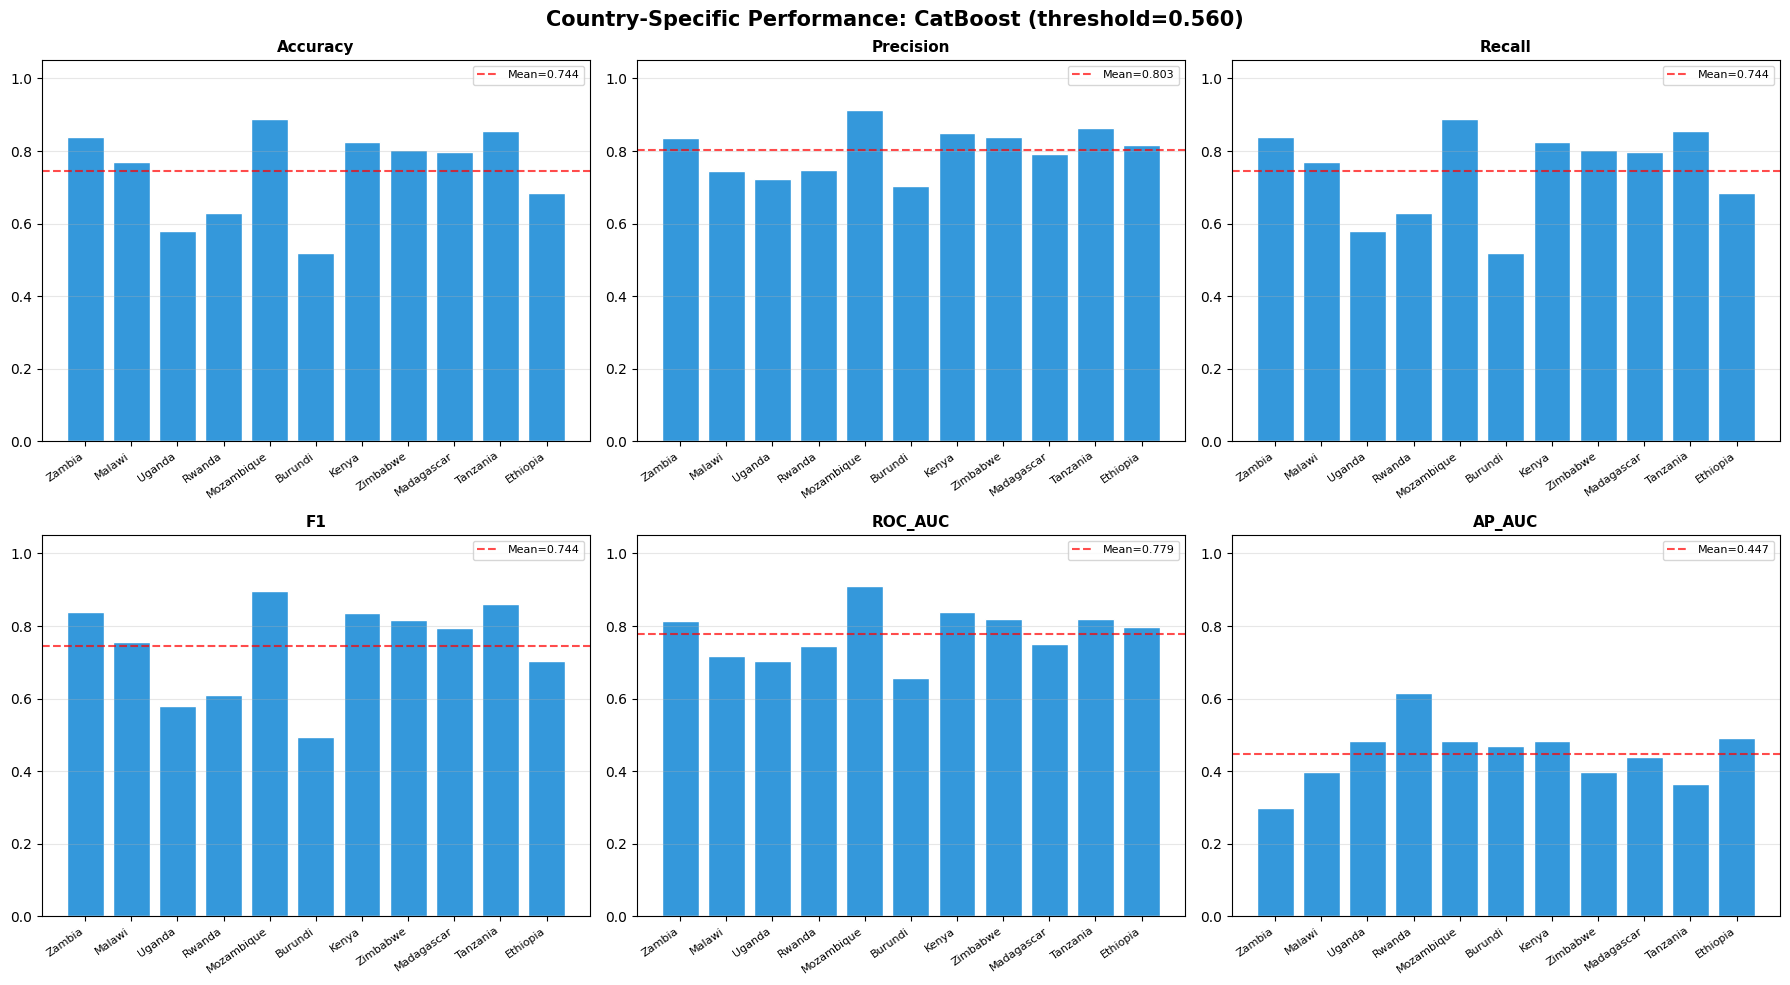

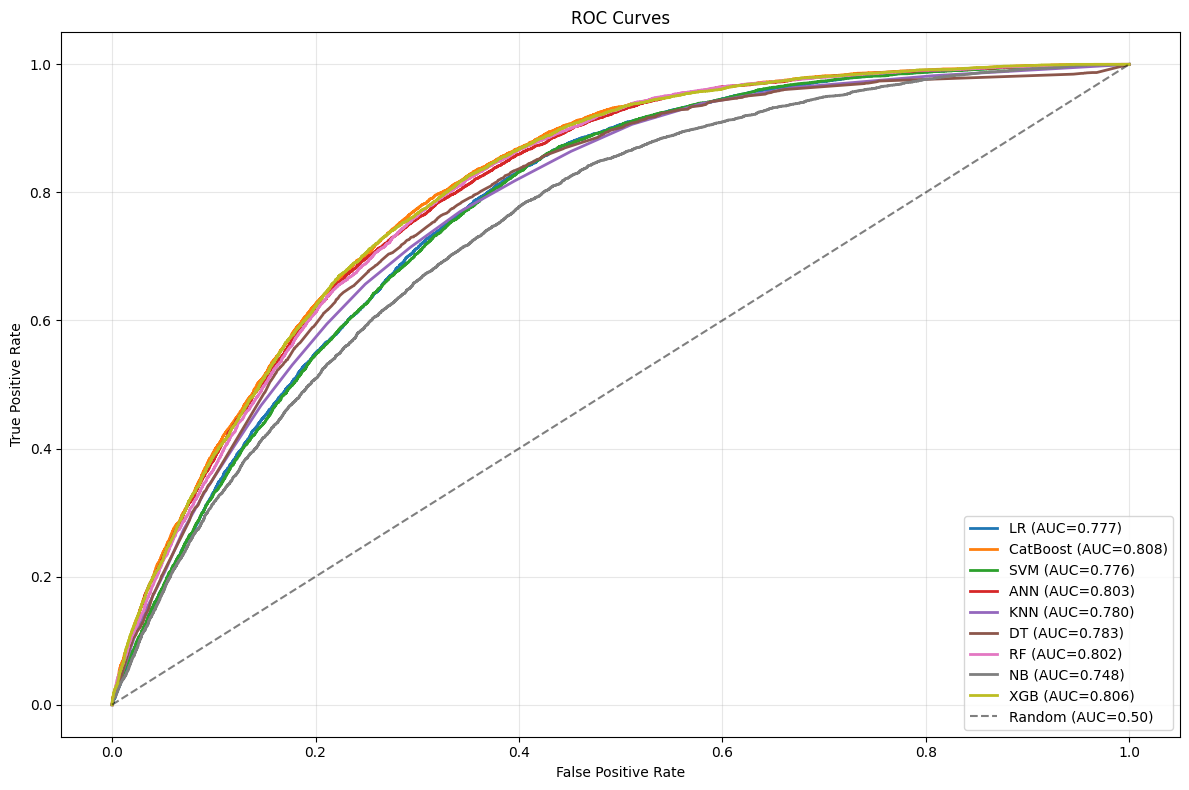

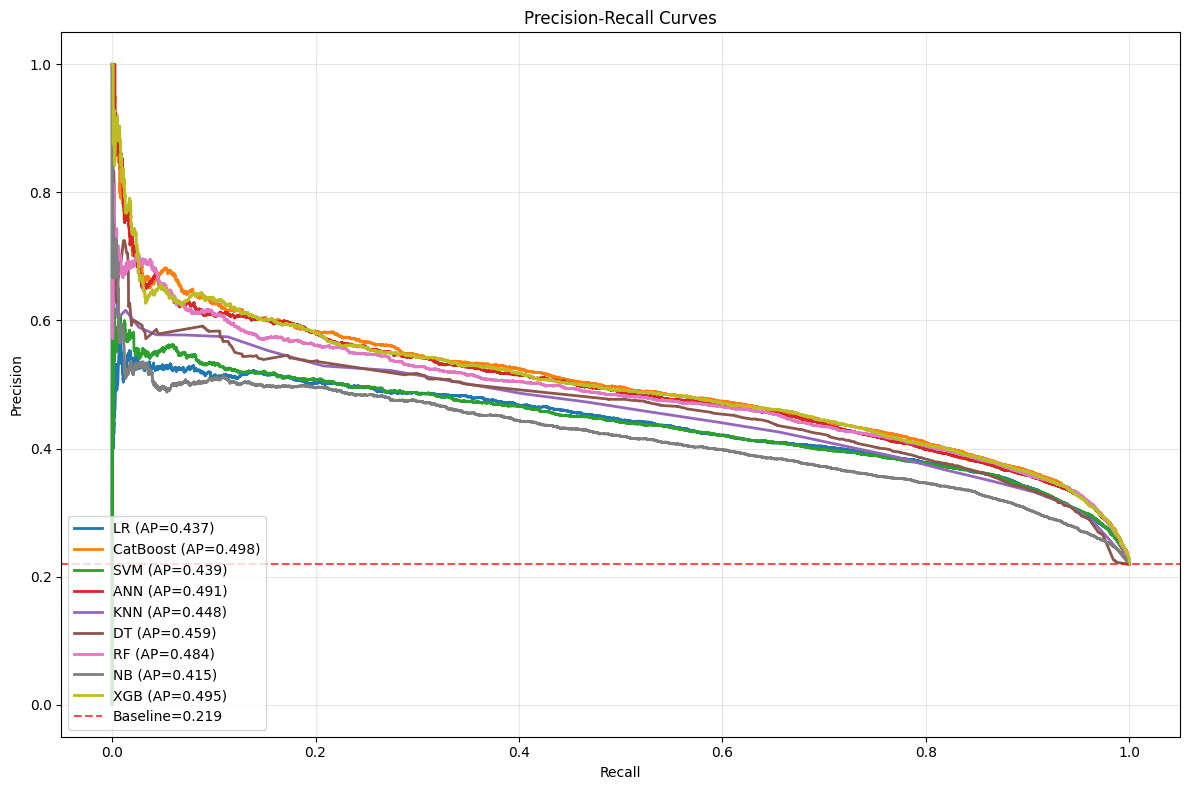

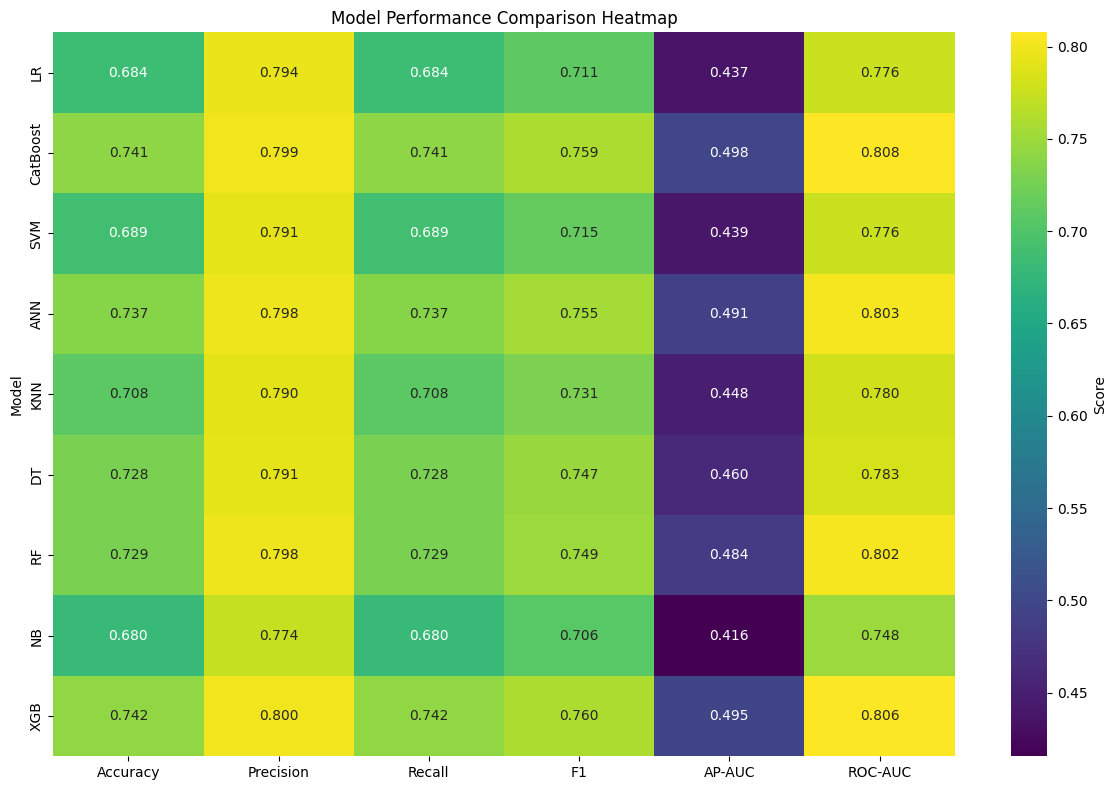


✅  BEST MODEL SAVED
  Model              : CatBoost
  Fixed threshold    : 0.560  (selected from train-set OOF predictions only)
  AP-AUC             : 0.4983 (0.4854-0.5116)
  ROC-AUC            : 0.8077 (0.8021-0.8133)
  Accuracy           : 0.7411 (0.7362-0.7461)
  Precision          : 0.7988 (0.7940-0.8036)
  Recall             : 0.7411 (0.7360-0.7462)
  F1-Score           : 0.7587 (0.7541-0.7630)

✅ All outputs saved to: C:\Users\wub\Desktop\ABC\CBA


In [1]:
# ============================================================
# FULL ML PIPELINE+ BayesSearchCV
# ============================================================

import re
import difflib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.preprocessing._encoders")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.parallel")

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from scipy.stats import randint, uniform, loguniform  # kept for compatibility, but not used
from statsmodels.stats.outliers_influence import variance_inflation_factor
import joblib
from collections import Counter

# ---------- NEW: BayesSearchCV imports ----------
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
# ------------------------------------------------

OUTPUT_PATH = r"C:\Users\wub\Desktop\ABC\CBA"

# ============================================================
# 1. CUSTOM TRANSFORMERS (unchanged)
# ============================================================

class CorrelationVIFSelector(BaseEstimator, TransformerMixin):
    """Removes correlated & high-VIF features"""
    def __init__(self, corr_threshold=0.9, vif_threshold=10, protect_indices=None):
        self.corr_threshold = corr_threshold
        self.vif_threshold = vif_threshold
        self.protect_indices = protect_indices if protect_indices is not None else []
        self.keep_indices_ = None

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        n_features = X.shape[1]
        if n_features <= 1:
            self.keep_indices_ = np.arange(n_features)
            return self

        protected = set(self.protect_indices)
        corr = np.corrcoef(X, rowvar=False)
        corr = np.nan_to_num(corr, nan=0.0)
        high_corr_pairs = []
        for i in range(n_features):
            for j in range(i + 1, n_features):
                if abs(corr[i, j]) > self.corr_threshold:
                    high_corr_pairs.append((i, j))
        mean_abs_corr = np.mean(np.abs(corr), axis=0)
        drop_set = set()
        for i, j in high_corr_pairs:
            if i in drop_set or j in drop_set:
                continue
            if i in protected and j in protected:
                continue  # never drop two protected features against each other
            if i in protected:
                drop_set.add(j)
            elif j in protected:
                drop_set.add(i)
            else:
                if mean_abs_corr[i] >= mean_abs_corr[j]:
                    drop_set.add(i)
                else:
                    drop_set.add(j)
        keep_indices = [i for i in range(n_features) if i not in drop_set]

        unprotected_remaining = [i for i in keep_indices if i not in protected]
        if len(unprotected_remaining) >= 2:
            X_rem = X[:, unprotected_remaining]
            stds = np.std(X_rem, axis=0)
            non_const = [idx for idx, s in enumerate(stds) if s > 1e-10]
            if len(non_const) >= 2:
                X_vif = X_rem[:, non_const]
                vif_data = np.zeros(len(non_const))
                for idx in range(len(non_const)):
                    try:
                        vif_data[idx] = variance_inflation_factor(X_vif, idx)
                    except Exception:
                        vif_data[idx] = 0.0
                vif_drop_rel = [non_const[i] for i, v in enumerate(vif_data) if v >= self.vif_threshold]
                vif_drop_abs = [unprotected_remaining[i] for i in vif_drop_rel]
                keep_indices = [i for i in keep_indices if i not in vif_drop_abs]

        self.keep_indices_ = np.array(sorted(set(keep_indices) | protected))
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.keep_indices_]


class RFSelectorKeepProtected(BaseEstimator, TransformerMixin):
    """RF-based embedded feature selection"""
    def __init__(self, n_estimators=100, random_state=42, n_jobs=1, threshold='median', keep_indices=None):
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.n_jobs = n_jobs
        self.threshold = threshold
        self.keep_indices = keep_indices if keep_indices is not None else []
        self.support_ = None
        self.feature_importances_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.rf_ = RandomForestClassifier(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=self.n_jobs,
        )
        self.rf_.fit(X, y)
        self.feature_importances_ = self.rf_.feature_importances_
        if self.threshold == 'median':
            thresh = np.median(self.feature_importances_)
        elif self.threshold == 'mean':
            thresh = np.mean(self.feature_importances_)
        else:
            thresh = float(self.threshold)
        keep_set = set(self.keep_indices)
        self.support_ = np.array([
            (i in keep_set) or (self.feature_importances_[i] >= thresh)
            for i in range(len(self.feature_importances_))
        ])
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.support_]


class CleanCommunityTransformer(BaseEstimator, TransformerMixin):
    """Cleans community variables: strips '%', converts to numeric, handles missing."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if isinstance(X, pd.DataFrame):
            for col in X.columns:
                if X[col].dtype == 'object':
                    X[col] = X[col].str.replace('%', '', regex=False).str.strip()
                    X[col] = pd.to_numeric(X[col], errors='coerce')
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return None
        return np.asarray(input_features, dtype=object)


# ============================================================
# 2. CATBOOST WRAPPER
# ============================================================
class CatBoostSklearnWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=500, depth=6, learning_rate=0.05,
                 l2_leaf_reg=3.0, border_count=128, random_strength=1.0,
                 bagging_temperature=1.0, min_data_in_leaf=1,
                 auto_class_weights="Balanced", verbose=0, random_state=42,
                 thread_count=2):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg
        self.border_count = border_count
        self.random_strength = random_strength
        self.bagging_temperature = bagging_temperature
        self.min_data_in_leaf = min_data_in_leaf
        self.auto_class_weights = auto_class_weights
        self.verbose = verbose
        self.random_state = random_state
        self.thread_count = thread_count

    def _make_model(self):
        return CatBoostClassifier(
            iterations=self.iterations,
            depth=self.depth,
            learning_rate=self.learning_rate,
            l2_leaf_reg=self.l2_leaf_reg,
            border_count=self.border_count,
            random_strength=self.random_strength,
            bagging_temperature=self.bagging_temperature,
            min_data_in_leaf=self.min_data_in_leaf,
            auto_class_weights=self.auto_class_weights,
            verbose=self.verbose,
            random_seed=self.random_state,
            thread_count=self.thread_count,
            allow_writing_files=False,
        )

    def fit(self, X, y):
        self.model_ = self._make_model()
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y).astype(int))
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float)).flatten().astype(int)

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))


# ============================================================
# 2b. ANN (MLP)
HIDDEN_LAYER_OPTIONS = {
    "64": (64,),
    "128": (128,),
    "64_64": (64, 64),
    "128_64": (128, 64),
    "256_128": (256, 128),
    "128_64_32": (128, 64, 32),
}


class MLPSklearnWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden_layer_sizes_code="64", activation="relu", solver="adam",
                 alpha=0.0001, learning_rate="constant", learning_rate_init=0.001,
                 batch_size=200, random_state=42, max_iter=500, early_stopping=True,
                 n_iter_no_change=15, validation_fraction=0.1):
        self.hidden_layer_sizes_code = hidden_layer_sizes_code
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate = learning_rate
        self.learning_rate_init = learning_rate_init
        self.batch_size = batch_size
        self.random_state = random_state
        self.max_iter = max_iter
        self.early_stopping = early_stopping
        self.n_iter_no_change = n_iter_no_change
        self.validation_fraction = validation_fraction

    def _make_model(self):
        return MLPClassifier(
            hidden_layer_sizes=HIDDEN_LAYER_OPTIONS[self.hidden_layer_sizes_code],
            activation=self.activation,
            solver=self.solver,
            alpha=self.alpha,
            learning_rate=self.learning_rate,
            learning_rate_init=self.learning_rate_init,
            batch_size=self.batch_size,
            random_state=self.random_state,
            max_iter=self.max_iter,
            early_stopping=self.early_stopping,
            n_iter_no_change=self.n_iter_no_change,
            validation_fraction=self.validation_fraction,
        )

    def fit(self, X, y):
        self.model_ = self._make_model()
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y))
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float))

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))


# ============================================================
# 3. HELPER FUNCTIONS (unchanged except threshold selection)
# ============================================================
def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns.str.strip().str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return df


def find_best_threshold(y_true, y_prob, thresholds=None, metric='f1_minority'):
    """
    Select threshold that maximizes a chosen metric on the validation set'.
    """
    if thresholds is None:
        thresholds = np.arange(0.01, 0.99, 0.01)
    best_thr, best_score = 0.5, -1
    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)
        if metric == 'f1_minority':
            score = f1_score(y_true, y_pred, average=None, zero_division=0)[1]
        elif metric == 'recall_minority':
            score = recall_score(y_true, y_pred, average=None, zero_division=0)[1]
        elif metric == 'gmean':
            rec = recall_score(y_true, y_pred, average=None, zero_division=0)
            score = np.sqrt(rec[0] * rec[1])
        else:
            score = f1_score(y_true, y_pred, average='weighted', zero_division=0)
        if score > best_score:
            best_score, best_thr = score, thr
    return best_thr


def bootstrap_ci(y_true, y_pred_or_prob, metric, n=2000, alpha=0.95):
    scores = []
    y_true = np.asarray(y_true)
    y_pred_or_prob = np.asarray(y_pred_or_prob)
    for _ in range(n):
        idx = resample(range(len(y_true)), replace=True)
        try:
            scores.append(metric(y_true[idx], y_pred_or_prob[idx]))
        except Exception:
            continue
    if not scores:
        return np.nan, np.nan, np.nan
    lower = np.percentile(scores, (1 - alpha) / 2 * 100)
    upper = np.percentile(scores, (1 + alpha) / 2 * 100)
    return np.mean(scores), lower, upper


def bootstrap_all_metrics_ci(y_true, y_pred, y_prob, n=2000):
    results = {}
    for name, func in [
        ('accuracy', accuracy_score),
        ('precision', lambda yt, yp: precision_score(yt, yp, average='weighted', zero_division=0)),
        ('recall', lambda yt, yp: recall_score(yt, yp, average='weighted', zero_division=0)),
        ('f1', lambda yt, yp: f1_score(yt, yp, average='weighted', zero_division=0)),
    ]:
        results[name] = bootstrap_ci(y_true, y_pred, func, n=n)
    results['ap_auc'] = bootstrap_ci(y_true, y_prob, average_precision_score, n=n)
    results['roc_auc'] = bootstrap_ci(y_true, y_prob, roc_auc_score, n=n)
    return results


def get_oof_probabilities(fitted_pipeline_template, X, y, cv_folds, model_name="model"):
    oof_prob = np.full(len(y), np.nan)
    for fold_i, (train_idx, val_idx) in enumerate(cv_folds):
        Xtr, ytr = X.iloc[train_idx], y.iloc[train_idx]
        Xvl = X.iloc[val_idx]
        try:
            m = clone(fitted_pipeline_template)
            m.fit(Xtr, ytr)
            if hasattr(m, "predict_proba"):
                prob = m.predict_proba(Xvl)[:, 1]
            else:
                prob = m.predict(Xvl).astype(float)
            oof_prob[val_idx] = prob
        except Exception as e:
            print(f"    ⚠ {model_name}: fold {fold_i} failed ({type(e).__name__}: {e}). "
                  f"Leaving these rows as NaN (excluded from threshold/CI calc).")
            continue
    return oof_prob


def evaluate_country_metrics(model, X, y_true, country_series, countries, threshold):
    y_true = np.asarray(y_true)
    y_prob = model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    country_arr = np.asarray(country_series)
    rows = []
    for country in countries:
        mask = country_arr == country
        if mask.sum() == 0:
            continue
        yt, yp, yprob = y_true[mask], y_pred[mask], y_prob[mask]
        row = {
            'Country': country,
            'Support': int(mask.sum()),
            'Accuracy': accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp, average='weighted', zero_division=0),
            'Recall': recall_score(yt, yp, average='weighted', zero_division=0),
            'F1': f1_score(yt, yp, average='weighted', zero_division=0),
        }
        if len(np.unique(yt)) >= 2:
            row['ROC_AUC'] = roc_auc_score(yt, yprob)
            row['AP_AUC'] = average_precision_score(yt, yprob)
        else:
            row['ROC_AUC'] = np.nan
            row['AP_AUC'] = np.nan
        rows.append(row)
    return pd.DataFrame(rows)


# ============================================================
# 4. LOAD RAW DATA (unchanged)
# ============================================================
train_raw = pd.read_csv(r"C:\Users\wub\desktop\train_data.csv", encoding="utf-8-sig")
test_raw = pd.read_csv(r"C:\Users\wub\desktop\test_data.csv", encoding="utf-8-sig")

train_raw = clean_columns(train_raw)
test_raw = clean_columns(test_raw)

TARGET = "water_access"
train_raw[TARGET] = train_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
test_raw[TARGET] = test_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
train_raw = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
test_raw = test_raw.dropna(subset=[TARGET]).reset_index(drop=True)

ID_COLS = ['case_identification', 'cluster_number', 'clusterid', 'household_sample_weight']
X_raw_train = train_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_train = train_raw[TARGET].astype(int)
X_raw_test = test_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_test = test_raw[TARGET].astype(int)

country_train = X_raw_train['country'].copy() if 'country' in X_raw_train.columns else pd.Series(['Unknown'] * len(X_raw_train))
country_test = X_raw_test['country'].copy() if 'country' in X_raw_test.columns else pd.Series(['Unknown'] * len(X_raw_test))

# ============================================================
# 5. FEATURE LISTS AND ONE-HOT CATEGORIES (unchanged)
# ============================================================
binary_vars = [
    "type_of_place_of_residence", "has_electricity", "sex_of_head_of_household",
    "household_water_treatment", "shared_toilets_with_others",
    "handwashing_place_observed", "number_of_households_members",
    "items_present_soap_or_detergent", "household_media_exposure",
    "sanitation_status", "housing_material_status"
]
onehot_vars = ["person_fetching_water", "current_marital_status", "country",
               "children_under5_group", "age_of_household_head"]
ordinal_vars = ["highest_educational_level_attained", "wealth_index_combined"]
community_vars = [
    "community_level_education", "community_level_electricity",
    "community_level_water_treatment", "community_level_media_exposure",
    "community_level_toilet", "community_level_poverty"
]

person_cats = sorted(X_raw_train["person_fetching_water"].dropna().unique())
marital_cats = sorted(X_raw_train["current_marital_status"].dropna().unique())

country_cats = sorted(X_raw_train["country"].dropna().unique())
children_cats = sorted(X_raw_train["children_under5_group"].dropna().unique())
age_cats = sorted(X_raw_train["age_of_household_head"].dropna().unique())

onehot_categories = [person_cats_keep, marital_cats_keep, country_cats, children_cats, age_cats]

# ============================================================
# 6. BUILD COLUMN TRANSFORMER (unchanged)
# ============================================================
binary_categories = {
    "type_of_place_of_residence": ["rural", "urban"],
    "has_electricity": ["no", "yes"],
    "sex_of_head_of_household": ["female", "male"],
    "household_water_treatment": ["no", "yes"],
    "shared_toilets_with_others": ["no", "yes"],
    "handwashing_place_observed": ["no", "yes"],
    "number_of_households_members": ["<4", ">=4"],
    "items_present_soap_or_detergent": ["no", "yes"],
    "household_media_exposure": ["No", "Yes"],
    "sanitation_status": ["unimproved_sanitation", "improved_sanitation"],
    "housing_material_status": ["unimproved_housing_material", "improved_housing_material"]
}
binary_categories_list = [binary_categories[col] for col in binary_vars]

binary_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=binary_categories_list))
])

onehot_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(categories=onehot_categories, drop='first',
                              handle_unknown='ignore', sparse_output=False))
])

ordinal_categories = [
    ["No education", "Primary", "Secondary", "Higher"],
    ["Poorest", "Poorer", "Middle", "Richer", "Richest"]
]
ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories))
])

community_transformer = Pipeline([
    ('clean_convert', CleanCommunityTransformer()),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

all_special = set(binary_vars + onehot_vars + ordinal_vars + community_vars)
numeric_cols = [col for col in X_raw_train.columns if col not in all_special]

preprocessor = ColumnTransformer([
    ('binary', binary_transformer, binary_vars),
    ('onehot', onehot_transformer, onehot_vars),
    ('ordinal', ordinal_transformer, ordinal_vars),
    ('community', community_transformer, community_vars),
    ('numeric', numeric_transformer, numeric_cols)
])

# ============================================================
# 7. IDENTIFY PROTECTED FEATURE INDICES (unchanged, but print fixed)
# ============================================================
preprocessor.fit(X_raw_train.iloc[:5])
feature_names = preprocessor.get_feature_names_out()

def _norm(s):
    s = str(s).lower()
    s = re.sub(r'[^a-z0-9<>]+', '', s)
    return s


def _build_candidate_map():
    cand = {}
    for col in binary_vars + ordinal_vars + community_vars + numeric_cols:
        cand[_norm(col)] = col
    for col, cats in zip(onehot_vars, onehot_categories):
        for c in cats:
            label = f"{col}_{c}"
            cand[_norm(label)] = label
    return cand


def find_protected_indices(terms, feat_names, sim_threshold=0.55):
    norm_feats = [_norm(fn.split('__', 1)[-1]) for fn in feat_names]
    cand_map = _build_candidate_map()
    cand_keys = list(cand_map.keys())
    idx_set, report = set(), []
    for term in terms:
        nterm = _norm(term)
        hits = [i for i, fn in enumerate(norm_feats) if nterm in fn or fn in nterm]
        if hits:
            idx_set.update(hits)
            report.append((term, [feat_names[i] for i in hits], 'direct'))
            continue
        close = difflib.get_close_matches(nterm, cand_keys, n=1, cutoff=sim_threshold)
        if close:
            hits = [i for i, fn in enumerate(norm_feats) if close[0] in fn or fn in close[0]]
            if hits:
                idx_set.update(hits)
                report.append((term, [feat_names[i] for i in hits], f'fuzzy~{close[0]}'))
                continue
        report.append((term, [], 'NOT FOUND'))
    return sorted(idx_set), report


protect_indices, match_report = find_protected_indices(PROTECTED_TERMS, feature_names)
for term, matched, how in match_report:
    status = "❌ NOT FOUND — please check spelling / list above" if how == 'NOT FOUND' else f"✅ [{how}]"
# ============================================================
# 8. CLASS WEIGHTS (unchanged)
# ============================================================
counter = Counter(y_train)
majority = max(counter, key=counter.get)
minority = min(counter, key=counter.get)
scale_pos_weight = counter[majority] / counter[minority]
classes = np.unique(y_train)
class_weights_dict = {cls: w for cls, w in zip(classes, compute_class_weight('balanced', classes=classes, y=y_train))}
_priors = np.array(list(class_weights_dict.values()))
class_prior_array = _priors / _priors.sum()

print("Class distribution:", counter)
print(f"Scale pos weight (XGB): {scale_pos_weight:.4f}")

# ============================================================
# 9. MODELS AND PARAMETER DISTRIBUTIONS — skopt spaces
# ------------------------------------------------------------
# Reordered per request: LR, CatBoost, SVM, ANN, KNN, DT, RF, NB, XGB
# ============================================================
base_models = {
    "LR": LogisticRegression(max_iter=1000, random_state=42, class_weight=class_weights_dict,
                              solver="saga", n_jobs=1),
    "CatBoost": CatBoostSklearnWrapper(verbose=0, random_state=42, auto_class_weights="Balanced",
                                        thread_count=2),
    "SVM": SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-3,
                          random_state=42, class_weight=class_weights_dict),
    "ANN": MLPSklearnWrapper(random_state=42, max_iter=500, early_stopping=True,
                              n_iter_no_change=15, validation_fraction=0.1),
    "KNN": KNeighborsClassifier(n_jobs=1),
    "DT": DecisionTreeClassifier(random_state=42, class_weight=class_weights_dict),
    "RF": RandomForestClassifier(random_state=42, class_weight=class_weights_dict, n_jobs=1),
    "NB": GaussianNB(priors=class_prior_array),
    "XGB": XGBClassifier(eval_metric="logloss", use_label_encoder=False, random_state=42,
                          scale_pos_weight=scale_pos_weight, tree_method="hist", n_jobs=1),
}

# Parameter spaces using skopt.space objects (reordered to match base_models)
param_distributions = {
    "LR": {
        "clf__C": Real(1e-3, 100, prior='log-uniform'),
        "clf__penalty": Categorical(["l1", "l2"]),
        "clf__solver": Categorical(["liblinear", "saga"]),
        "clf__max_iter": Integer(500, 3000),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "CatBoost": {
        "clf__iterations": Integer(200, 600),
        "clf__depth": Integer(4, 8),
        "clf__learning_rate": Real(0.005, 0.2, prior='log-uniform'),
        "clf__l2_leaf_reg": Real(1, 11),
        "clf__border_count": Integer(64, 254),
        "clf__random_strength": Real(0.1, 10.1),
        "clf__bagging_temperature": Real(0, 1),
        "clf__min_data_in_leaf": Integer(1, 50),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "SVM": {
        "clf__alpha": Real(1e-6, 1, prior='log-uniform'),
        "clf__loss": Categorical(["log_loss", "modified_huber"]),
        "clf__penalty": Categorical(["l2", "elasticnet"]),
        "clf__l1_ratio": Real(0.05, 0.95),
        "clf__max_iter": Integer(2000, 5000),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "ANN": {
        "clf__hidden_layer_sizes_code": Categorical(list(HIDDEN_LAYER_OPTIONS.keys())),
        "clf__activation": Categorical(["relu", "tanh"]),
        "clf__solver": Categorical(["adam"]),
        "clf__alpha": Real(1e-5, 0.1, prior='log-uniform'),
        "clf__learning_rate": Categorical(["constant", "adaptive"]),
        "clf__learning_rate_init": Real(1e-4, 1e-2, prior='log-uniform'),
        "clf__batch_size": Categorical([32, 64, 128, 256]),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "KNN": {
        "clf__n_neighbors": Integer(3, 30),
        "clf__weights": Categorical(["uniform", "distance"]),
        "clf__algorithm": Categorical(["ball_tree", "kd_tree"]),
        "clf__metric": Categorical(["euclidean", "manhattan"]),
        "clf__leaf_size": Integer(20, 50),
        "clf__p": Categorical([1, 2]),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "DT": {
        "clf__max_depth": Categorical([3, 5, 8, 12, None]),
        "clf__min_samples_split": Integer(2, 20),
        "clf__min_samples_leaf": Integer(1, 8),
        "clf__criterion": Categorical(["gini", "entropy", "log_loss"]),
        "clf__min_impurity_decrease": Real(0, 0.01),
        "clf__ccp_alpha": Real(1e-5, 1e-1, prior='log-uniform'),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "RF": {
        "clf__n_estimators": Integer(100, 600),
        "clf__max_depth": Categorical([5, 10, 20, None]),
        "clf__min_samples_split": Integer(2, 15),
        "clf__min_samples_leaf": Integer(1, 10),
        "clf__max_features": Categorical(["sqrt", "log2"]),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "NB": {
        "clf__var_smoothing": Real(1e-11, 1e-5, prior='log-uniform'),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
    "XGB": {
        "clf__n_estimators": Integer(100, 500),
        "clf__max_depth": Integer(3, 10),
        "clf__learning_rate": Real(0.01, 0.3, prior='log-uniform'),
        "clf__subsample": Real(0.5, 1.0),
        "clf__colsample_bytree": Real(0.5, 1.0),
        "clf__gamma": Real(1e-3, 5, prior='log-uniform'),
        "clf__min_child_weight": Integer(1, 10),
        "clf__reg_alpha": Real(0, 1),
        "clf__reg_lambda": Real(1, 4),
        "rf_select__threshold": Categorical(['median', 'mean', 0.01, 0.001]),
    },
}

# Search n_jobs settings (unchanged)
SEARCH_N_JOBS = {"CatBoost": 2, "ANN": 2}
DEFAULT_SEARCH_N_JOBS = -1

# ============================================================
# 10. PIPELINE FACTORY (unchanged)
# ============================================================
def make_pipeline_with_hybrid_selection(classifier):
    return Pipeline([
        ('prep', preprocessor),
        ('corr_vif', CorrelationVIFSelector(corr_threshold=0.7, vif_threshold=5,
                                             protect_indices=protect_indices)),
        ('rf_select', RFSelectorKeepProtected(n_estimators=100, random_state=42, n_jobs=1,
                                               threshold='median', keep_indices=protect_indices)),
        ('clf', classifier)
    ])

# ============================================================
# 11. HYPERPARAMETER TUNING (inner CV) + OOF THRESHOLD SELECTION (outer CV)
# ============================================================
cv_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

best_models = {}
model_thresholds = {}
cv_results = []
failed_models = []

print("\n" + "=" * 80)
print("STARTING HYPERPARAMETER TUNING + OOF THRESHOLD SELECTION (train set only)")
print("=" * 80)

for name, base_clf in base_models.items():
    print(f"\n{'='*60}\nProcessing model: {name}\n{'='*60}")
    try:
        pipeline = make_pipeline_with_hybrid_selection(base_clf)
        n_jobs_search = SEARCH_N_JOBS.get(name, DEFAULT_SEARCH_N_JOBS)

        # ---------- REPLACED: BayesSearchCV instead of RandomizedSearchCV ----------
        search = BayesSearchCV(
            pipeline, param_distributions[name], n_iter=20, cv=inner_cv,
            scoring='average_precision', random_state=42, n_jobs=n_jobs_search, verbose=1,
        )
        # --------------------------------------------------------------------------
        search.fit(X_raw_train, y_train)
        best_model = search.best_estimator_
        best_models[name] = best_model

        print("  ✅ Best parameters:")
        for p, v in search.best_params_.items():
            print(f"     {p}: {v}")
        print(f"  Best inner CV AP-AUC: {search.best_score_:.4f}")

        # --- OOF predictions on the training set ---
        cv_folds = list(cv_outer.split(X_raw_train, y_train))
        print("  Generating out-of-fold predictions (train set only)...")
        oof_prob = get_oof_probabilities(best_model, X_raw_train, y_train, cv_folds, model_name=name)

        valid_mask = ~np.isnan(oof_prob)
        if valid_mask.sum() < 0.5 * len(y_train):
            raise RuntimeError(f"Too many OOF folds failed for {name} "
                                f"({valid_mask.sum()}/{len(y_train)} valid) — skipping model.")

        y_oof = y_train.values[valid_mask]
        p_oof = oof_prob[valid_mask]

        # Threshold selection using minority F1 (unchanged)
        best_thr = find_best_threshold(y_oof, p_oof, metric='f1_minority')
        model_thresholds[name] = best_thr
        y_oof_pred = (p_oof >= best_thr).astype(int)

        oof_ci = bootstrap_all_metrics_ci(y_oof, y_oof_pred, p_oof)

        cv_results.append({
            "Model": name,
            "Threshold_from_OOF": f"{best_thr:.3f}",
            "CV_Accuracy": f"{oof_ci['accuracy'][0]:.3f} ({oof_ci['accuracy'][1]:.3f}-{oof_ci['accuracy'][2]:.3f})",
            "CV_Precision": f"{oof_ci['precision'][0]:.3f} ({oof_ci['precision'][1]:.3f}-{oof_ci['precision'][2]:.3f})",
            "CV_Recall": f"{oof_ci['recall'][0]:.3f} ({oof_ci['recall'][1]:.3f}-{oof_ci['recall'][2]:.3f})",
            "CV_F1": f"{oof_ci['f1'][0]:.3f} ({oof_ci['f1'][1]:.3f}-{oof_ci['f1'][2]:.3f})",
            "CV_ROC_AUC": f"{oof_ci['roc_auc'][0]:.3f} ({oof_ci['roc_auc'][1]:.3f}-{oof_ci['roc_auc'][2]:.3f})",
            "CV_AP_AUC": f"{oof_ci['ap_auc'][0]:.3f} ({oof_ci['ap_auc'][1]:.3f}-{oof_ci['ap_auc'][2]:.3f})",
        })
        print(f"  OOF-derived threshold: {best_thr:.3f}  |  "
              f"AP-AUC={oof_ci['ap_auc'][0]:.3f}  ROC-AUC={oof_ci['roc_auc'][0]:.3f}")

    except Exception as e:
        print(f"  ❌ {name} FAILED and was skipped: {type(e).__name__}: {e}")
        failed_models.append((name, str(e)))
        continue

cv_df = pd.DataFrame(cv_results)
cv_df.to_csv(f"{OUTPUT_PATH}/cv_performance_table.csv", index=False)
print("\n✅ Cross-Validation (OOF) Results Saved")

if failed_models:
    with open(f"{OUTPUT_PATH}/failed_models.log", "w") as f:
        for name, err in failed_models:
            f.write(f"{name}: {err}\n")
    print(f"⚠ {len(failed_models)} model(s) failed and were skipped — see failed_models.log")

# ============================================================
# 12–17: TEST EVALUATION, BEST MODEL SELECTION, PLOTS, SAVING — ALL UNCHANGED
# ============================================================

test_results = []
print("\n" + "=" * 80)
print("TEST SET EVALUATION (20% held-out set, touched for the first time here)")
print("=" * 80)

for model_name, model in best_models.items():
    print(f"\n{'='*60}\nEvaluating: {model_name}\n{'='*60}")
    try:
        tuned_thr = model_thresholds[model_name]
        y_prob = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        y_pred = (y_prob >= tuned_thr).astype(int)

        ci = bootstrap_all_metrics_ci(y_test, y_pred, y_prob)
        acc_mean, acc_lo, acc_hi = ci['accuracy']
        prec_mean, prec_lo, prec_hi = ci['precision']
        rec_mean, rec_lo, rec_hi = ci['recall']
        f1_mean, f1_lo, f1_hi = ci['f1']
        roc_mean, roc_lo, roc_hi = ci['roc_auc']
        ap_mean, ap_lo, ap_hi = ci['ap_auc']

        print(f"  🔹 Fixed threshold (from train OOF): {tuned_thr:.3f}")
        print(f"  📊 Accuracy  : {acc_mean:.4f} ({acc_lo:.4f}-{acc_hi:.4f})")
        print(f"  📊 Precision : {prec_mean:.4f} ({prec_lo:.4f}-{prec_hi:.4f})")
        print(f"  📊 Recall    : {rec_mean:.4f} ({rec_lo:.4f}-{rec_hi:.4f})")
        print(f"  📊 F1        : {f1_mean:.4f} ({f1_lo:.4f}-{f1_hi:.4f})")
        print(f"  📊 ROC-AUC   : {roc_mean:.4f} ({roc_lo:.4f}-{roc_hi:.4f})")
        print(f"  📊 AP-AUC    : {ap_mean:.4f} ({ap_lo:.4f}-{ap_hi:.4f})")
        print(f"\n  Classification Report (threshold = {tuned_thr:.3f}):")
        print(classification_report(y_test, y_pred, zero_division=0))

        test_results.append({
            "Model": model_name, "Threshold": f"{tuned_thr:.3f}",
            "Accuracy": f"{acc_mean:.4f} ({acc_lo:.4f}-{acc_hi:.4f})",
            "Precision": f"{prec_mean:.4f} ({prec_lo:.4f}-{prec_hi:.4f})",
            "Recall": f"{rec_mean:.4f} ({rec_lo:.4f}-{rec_hi:.4f})",
            "F1_Score": f"{f1_mean:.4f} ({f1_lo:.4f}-{f1_hi:.4f})",
            "ROC_AUC": f"{roc_mean:.4f} ({roc_lo:.4f}-{roc_hi:.4f})",
            "AP_AUC": f"{ap_mean:.4f} ({ap_lo:.4f}-{ap_hi:.4f})",
            "ROC_AUC_Val": roc_mean, "AP_AUC_Val": ap_mean,
        })
    except Exception as e:
        print(f"  ❌ {model_name} FAILED at test evaluation: {type(e).__name__}: {e}")
        continue

test_df = pd.DataFrame(test_results)
test_df.to_csv(f"{OUTPUT_PATH}/test_performance_table.csv", index=False)
print("\n✅ Test Results Saved")

# ============================================================
# 13. SELECT BEST MODEL BY COMBINED RANK (AP + ROC)
# ============================================================
test_df['rank_AP'] = test_df['AP_AUC_Val'].rank(ascending=False)
test_df['rank_ROC'] = test_df['ROC_AUC_Val'].rank(ascending=False)
test_df['combined_rank'] = test_df['rank_AP'] + test_df['rank_ROC']

best_idx = test_df['combined_rank'].idxmin()
best_row = test_df.loc[best_idx]
best_model_name = best_row['Model']
best_model = best_models[best_model_name]
best_threshold = float(best_row['Threshold'])

print("\n" + "=" * 80)
print(f"🏆  BEST MODEL (by AP_AUC + ROC_AUC combined rank): {best_model_name}")
print(f"    Fixed threshold : {best_threshold:.3f}")
print(f"    AP-AUC          : {best_row['AP_AUC']} (rank {int(best_row['rank_AP'])})")
print(f"    ROC-AUC         : {best_row['ROC_AUC']} (rank {int(best_row['rank_ROC'])})")
print("=" * 80)

# ============================================================
# 14. COUNTRY-SPECIFIC METRICS (BEST MODEL ONLY)
# ============================================================
all_countries = country_test.unique()
best_country_df = evaluate_country_metrics(best_model, X_raw_test, y_test, country_test,
                                            countries=all_countries, threshold=best_threshold)
best_country_df.to_csv(f"{OUTPUT_PATH}/country_metrics_best_model.csv", index=False)
print("\nCountry-specific metrics (best model):")
print(best_country_df.to_string(index=False))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'AP_AUC']
country_plot = best_country_df.set_index('Country')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, metric in enumerate(metrics_to_plot):
    vals = country_plot[metric].astype(float)
    axes[i].bar(vals.index, vals.values, color='#3498db', edgecolor='white')
    axes[i].set_title(metric, fontsize=11, fontweight='bold')
    axes[i].set_ylim(0, 1.05)
    axes[i].set_xticklabels(vals.index, rotation=35, ha='right', fontsize=8)
    axes[i].axhline(y=np.nanmean(vals.values), color='red', linestyle='--', alpha=0.7,
                     label=f"Mean={np.nanmean(vals.values):.3f}")
    axes[i].legend(fontsize=8)
    axes[i].grid(axis='y', alpha=0.3)
plt.suptitle(f"Country-Specific Performance: {best_model_name} (threshold={best_threshold:.3f})",
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/country_metrics_best_model.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 15. ROC AND PR CURVES (ALL SUCCESSFULLY-FITTED MODELS)
# ============================================================
plt.figure(figsize=(12, 8))
for model_name, model in best_models.items():
    try:
        yp = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        fpr, tpr, _ = roc_curve(y_test, yp)
        roc = roc_auc_score(y_test, yp)
        plt.plot(fpr, tpr, label=f"{model_name} (AUC={roc:.3f})", linewidth=2)
    except Exception:
        continue
plt.plot([0, 1], [0, 1], 'k--', label="Random (AUC=0.50)", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves")
plt.legend(loc='lower right', fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/roc_curves.png", dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 8))
baseline = y_test.mean()
for model_name, model in best_models.items():
    try:
        yp = model.predict_proba(X_raw_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_raw_test).astype(float)
        precision, recall, _ = precision_recall_curve(y_test, yp)
        ap = average_precision_score(y_test, yp)
        plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})", linewidth=2)
    except Exception:
        continue
plt.axhline(y=baseline, linestyle='--', color='red', label=f"Baseline={baseline:.3f}", alpha=0.7)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves")
plt.legend(loc='lower left', fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/pr_curves.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 16. PERFORMANCE HEATMAP
# ============================================================
heatmap_data = test_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1_Score", "AP_AUC", "ROC_AUC"]].copy()
def extract_mean(s):
    return float(s.split()[0]) if isinstance(s, str) else float(s)
for col in heatmap_data.columns:
    heatmap_data[col] = heatmap_data[col].apply(extract_mean)
heatmap_data.columns = ["Accuracy", "Precision", "Recall", "F1", "AP-AUC", "ROC-AUC"]

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt=".3f", cbar_kws={'label': 'Score'})
plt.title("Model Performance Comparison Heatmap")
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/model_performance_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 17. SAVE BEST MODEL AND THRESHOLD
# ============================================================
joblib.dump(best_model, f"{OUTPUT_PATH}/best_model.pkl")
with open(f"{OUTPUT_PATH}/best_threshold.txt", "w") as f:
    f.write(f"{best_threshold:.3f}")

print("\n" + "=" * 80)
print("✅  BEST MODEL SAVED")
print("=" * 80)
print(f"  Model              : {best_model_name}")
print(f"  Fixed threshold    : {best_threshold:.3f}  (selected from train-set OOF predictions only)")
print(f"  AP-AUC             : {best_row['AP_AUC']}")
print(f"  ROC-AUC            : {best_row['ROC_AUC']}")
print(f"  Accuracy           : {best_row['Accuracy']}")
print(f"  Precision          : {best_row['Precision']}")
print(f"  Recall             : {best_row['Recall']}")
print(f"  F1-Score           : {best_row['F1_Score']}")
print("=" * 80)
print(f"\n✅ All outputs saved to: {OUTPUT_PATH}")

Loading saved best_model.pkl ...
  Loaded model: CatBoost  |  threshold: 0.560
  Test set: 29224 rows, 24 raw columns
  Train set: 116896 rows

SHAP FEATURE IMPORTANCE — CatBoost

Community-level column check (please verify against your own coding):
  Community Level Education: low=-1.0611 -> code 0, high=0.9424 -> code 1
  Community Level Electricity: low=-1.0853 -> code 0, high=0.9214 -> code 1
  Community Level Water Treatment: low=-1.0314 -> code 0, high=0.9695 -> code 1
  Community Level Media Exposure: low=-1.0417 -> code 0, high=0.9600 -> code 1
  Community Level Toilet: low=-1.0156 -> code 0, high=0.9847 -> code 1
  Community Level Poverty: low=-0.9297 -> code 0, high=1.0756 -> code 1

  No near-duplicate (|corr| > 0.99) feature pairs found.
  Using TreeExplainer (tree_path_dependent, margin/log-odds scale) -- robust and exact for CatBoost/XGB/RF/DT. E[f(X)] may be negative; this is expected.
  Explainer type: TreeExplainer
  Computing SHAP values on 1000 test rows for bar/bees

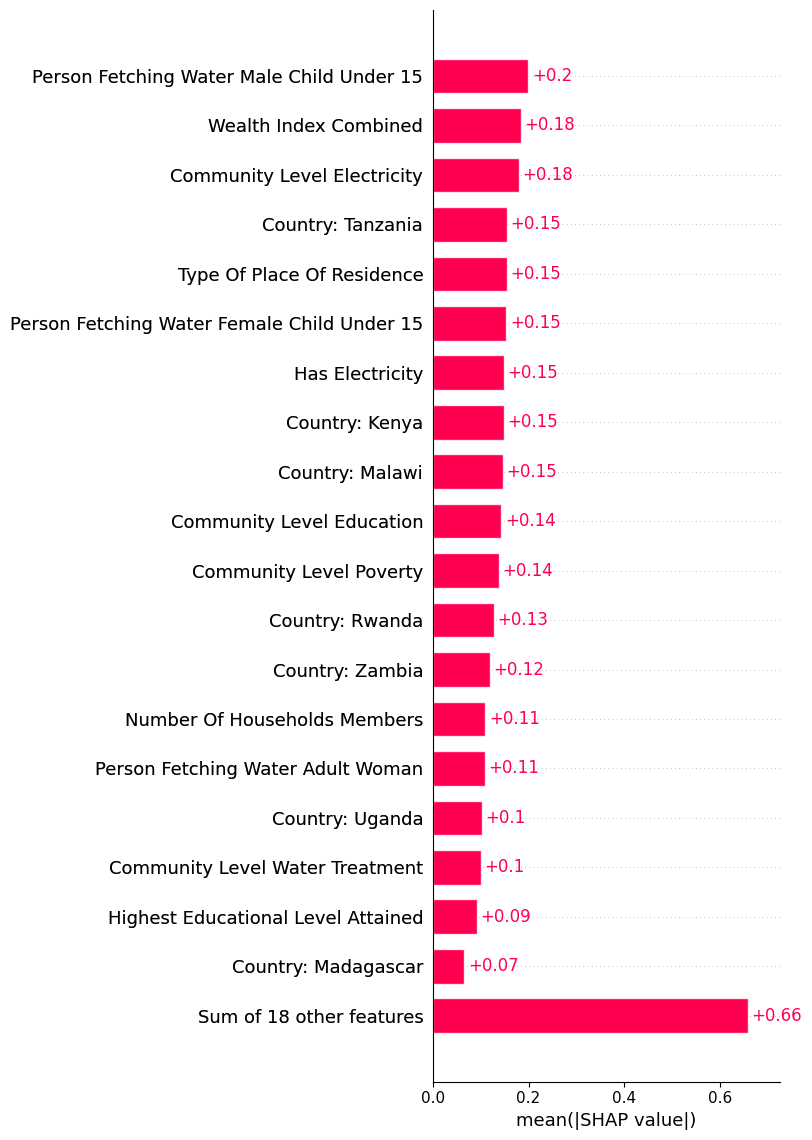

  ✅ SHAP bar plot saved


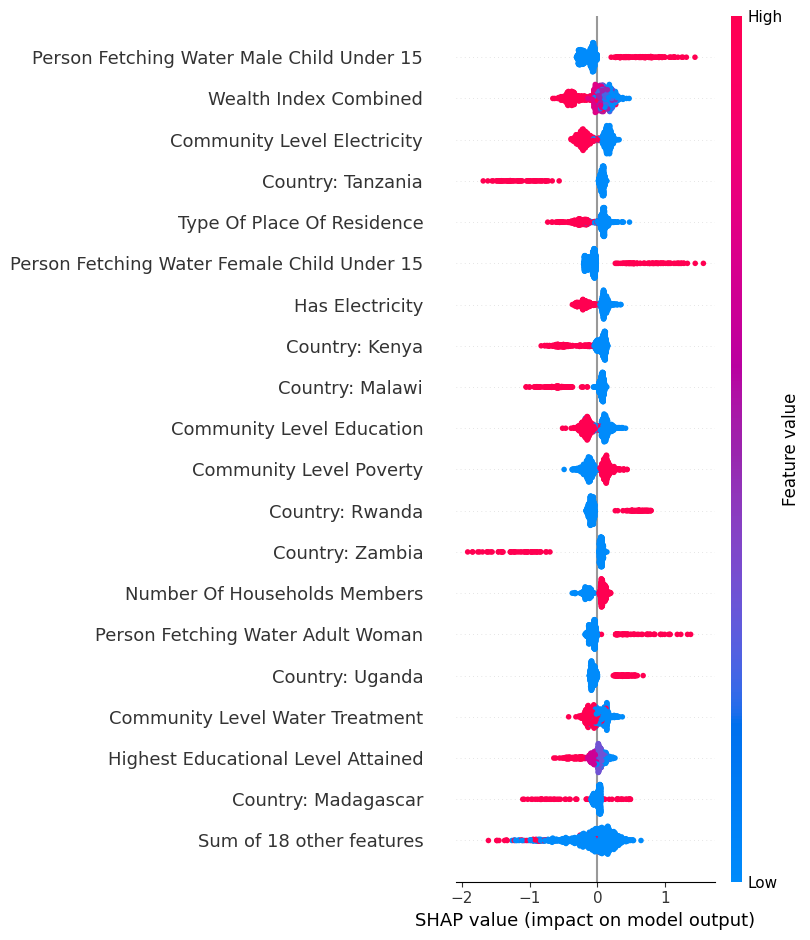

  ✅ SHAP summary (beeswarm) plot saved
  Waterfall: using probability-scale TreeExplainer (interventional) for this single instance.


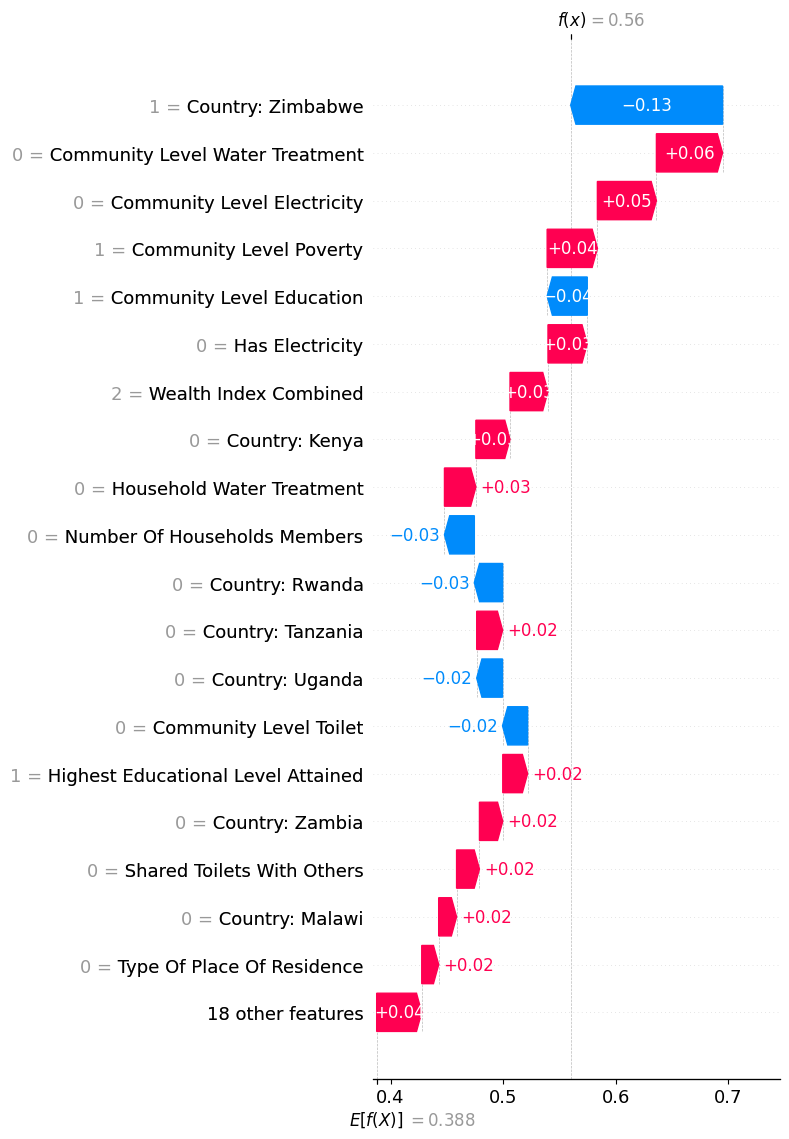

  ✅ SHAP waterfall plot saved (test row 5843) — publication-ready, probability scale
  Top 3 predictors by mean |SHAP|: [np.str_('Person Fetching Water Male Child Under 15'), np.str_('Wealth Index Combined'), np.str_('Community Level Electricity')]

Creating combined dependence plots for top 3 features...


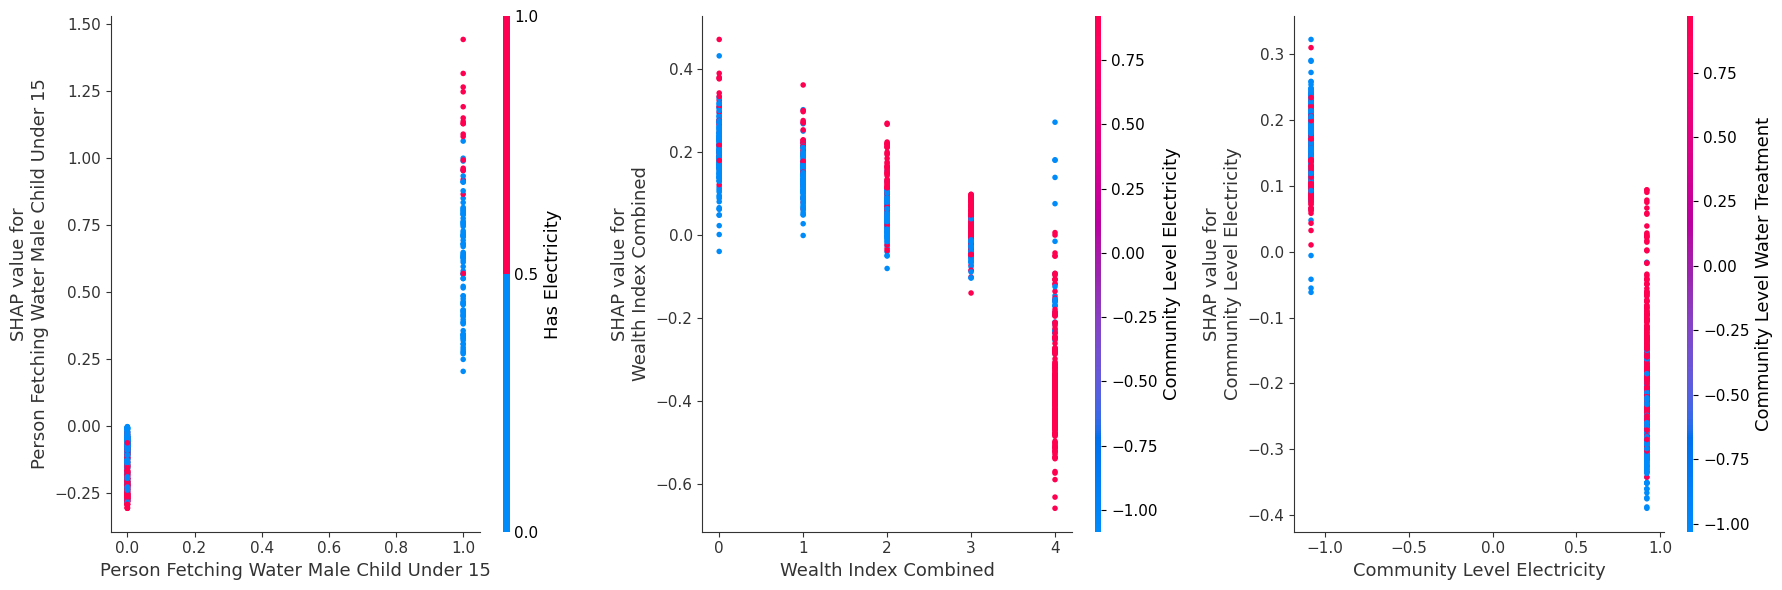

  ✅ Saved shap_dependence_top3_CatBoost.png


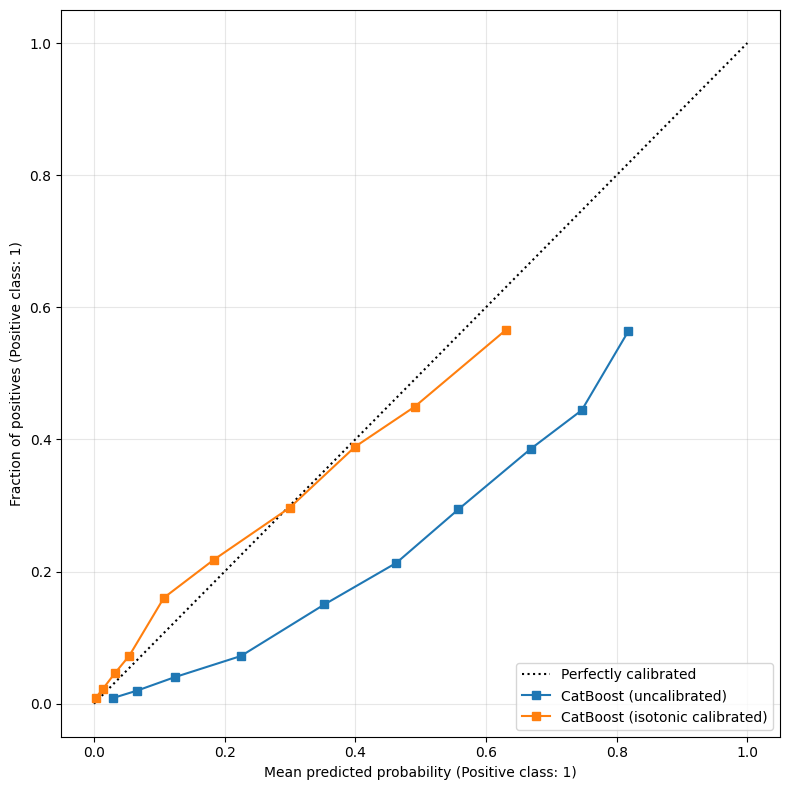

  ✅ Calibration curve (uncalibrated + isotonic) saved

✅ SHAP + CALIBRATION ANALYSIS COMPLETE
   Files written to: C:\Users\wub\Desktop\ABC\CBA
   - shap_bar_plot.png
   - shap_summary_plot.png
   - shap_waterfall_plot.png
   - shap_dependence_top3.png
   - calibration_curve.png


In [6]:
# ============================================================

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibrationDisplay
from sklearn.isotonic import IsotonicRegression

OUTPUT_PATH = r"C:\Users\wub\Desktop\ABC\CBA"
TRAIN_CSV_PATH = r"C:\Users\wub\desktop\train_data.csv"
TEST_CSV_PATH = r"C:\Users\wub\desktop\test_data.csv"
TARGET = "water_access"
ID_COLS = ['case_identification', 'cluster_number', 'clusterid', 'household_sample_weight']
SHAP_SAMPLE_SIZE = 1000
BACKGROUND_SAMPLE_SIZE = 100
NEAR_DUPLICATE_CORR_THRESHOLD = 0.99

warnings.filterwarnings(
    "ignore",
    message="Found unknown categories in columns.*",
    category=UserWarning,
)
# joblib.load()
# ============================================================
class CorrelationVIFSelector(BaseEstimator, TransformerMixin):
    def __init__(self, corr_threshold=0.5, vif_threshold=5, protect_indices=None):
        self.corr_threshold = corr_threshold
        self.vif_threshold = vif_threshold
        self.protect_indices = protect_indices if protect_indices is not None else []
        self.keep_indices_ = None

    def fit(self, X, y=None):
        raise NotImplementedError("fit()")

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.keep_indices_]


class RFSelectorKeepProtected(BaseEstimator, TransformerMixin):
    def __init__(self, n_estimators=100, random_state=42, n_jobs=1, threshold='median', keep_indices=None):
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.n_jobs = n_jobs
        self.threshold = threshold
        self.keep_indices = keep_indices if keep_indices is not None else []
        self.support_ = None
        self.feature_importances_ = None

    def fit(self, X, y):
        raise NotImplementedError("fit()-joblib already fitted.")

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return X[:, self.support_]


class CleanCommunityTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if isinstance(X, pd.DataFrame):
            for col in X.columns:
                if X[col].dtype == 'object':
                    X[col] = X[col].str.replace('%', '', regex=False).str.strip()
                    X[col] = pd.to_numeric(X[col], errors='coerce')
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return None
        return np.asarray(input_features, dtype=object)


class CatBoostSklearnWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=500, depth=6, learning_rate=0.05,
                 l2_leaf_reg=3.0, border_count=128, random_strength=1.0,
                 bagging_temperature=1.0, min_data_in_leaf=1,
                 auto_class_weights="Balanced", verbose=0, random_state=42,
                 thread_count=2):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg
        self.border_count = border_count
        self.random_strength = random_strength
        self.bagging_temperature = bagging_temperature
        self.min_data_in_leaf = min_data_in_leaf
        self.auto_class_weights = auto_class_weights
        self.verbose = verbose
        self.random_state = random_state
        self.thread_count = thread_count

    def _make_model(self):
        return CatBoostClassifier(
            iterations=self.iterations, depth=self.depth, learning_rate=self.learning_rate,
            l2_leaf_reg=self.l2_leaf_reg, border_count=self.border_count,
            random_strength=self.random_strength, bagging_temperature=self.bagging_temperature,
            min_data_in_leaf=self.min_data_in_leaf, auto_class_weights=self.auto_class_weights,
            verbose=self.verbose, random_seed=self.random_state, thread_count=self.thread_count,
            allow_writing_files=False,
        )

    def fit(self, X, y):
        self.model_ = self._make_model()
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y).astype(int))
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float)).flatten().astype(int)

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))


HIDDEN_LAYER_OPTIONS = {
    "64": (64,), "128": (128,), "64_64": (64, 64),
    "128_64": (128, 64), "256_128": (256, 128), "128_64_32": (128, 64, 32),
}


class MLPSklearnWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden_layer_sizes_code="64", activation="relu", solver="adam",
                 alpha=0.0001, learning_rate="constant", learning_rate_init=0.001,
                 batch_size=200, random_state=42, max_iter=500, early_stopping=True,
                 n_iter_no_change=15, validation_fraction=0.1):
        self.hidden_layer_sizes_code = hidden_layer_sizes_code
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate = learning_rate
        self.learning_rate_init = learning_rate_init
        self.batch_size = batch_size
        self.random_state = random_state
        self.max_iter = max_iter
        self.early_stopping = early_stopping
        self.n_iter_no_change = n_iter_no_change
        self.validation_fraction = validation_fraction

    def _make_model(self):
        return MLPClassifier(
            hidden_layer_sizes=HIDDEN_LAYER_OPTIONS[self.hidden_layer_sizes_code],
            activation=self.activation, solver=self.solver, alpha=self.alpha,
            learning_rate=self.learning_rate, learning_rate_init=self.learning_rate_init,
            batch_size=self.batch_size, random_state=self.random_state, max_iter=self.max_iter,
            early_stopping=self.early_stopping, n_iter_no_change=self.n_iter_no_change,
            validation_fraction=self.validation_fraction,
        )

    def fit(self, X, y):
        self.model_ = self._make_model()
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y))
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float))

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))


def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns.str.strip().str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return df


def infer_model_display_name(clf):
    mapping = {
        "CatBoostSklearnWrapper": "CatBoost",
        "MLPSklearnWrapper": "ANN",
        "LogisticRegression": "LR",
        "SGDClassifier": "SVM",
        "KNeighborsClassifier": "KNN",
        "DecisionTreeClassifier": "DT",
        "RandomForestClassifier": "RF",
        "GaussianNB": "NB",
        "XGBClassifier": "XGB",
    }
    return mapping.get(type(clf).__name__, type(clf).__name__)
FEATURE_LABEL_OVERRIDES = {
    # "wealth_index_combined": "Wealth index",
}

def clean_feature_name(name: str) -> str:
    if name in FEATURE_LABEL_OVERRIDES:
        return FEATURE_LABEL_OVERRIDES[name]

    if '_' in name:
        prefix, rest = name.split('_', 1)
        rest = rest.strip()
        looks_like_category = bool(rest) and (' ' in rest or rest[:1].isupper() or rest[:1].isdigit())
        if looks_like_category:
            prefix_label = PREFIX_LABEL_OVERRIDES.get(prefix.lower(), prefix.replace('_', ' ').capitalize())
            rest_label = rest[0].upper() + rest[1:] if rest else rest
            return f"{prefix_label}: {rest_label}"

    if name.lower() in PREFIX_LABEL_OVERRIDES:
        return PREFIX_LABEL_OVERRIDES[name.lower()]

    words = name.replace('_', ' ').strip().split(' ')
    return ' '.join(w.capitalize() for w in words if w)


# ============================================================
# 1. LOAD SAVED ARTIFACTS
# ============================================================
print("Loading saved best_model.pkl ...")
best_model = joblib.load(f"{OUTPUT_PATH}/best_model.pkl")

with open(f"{OUTPUT_PATH}/best_threshold.txt", "r") as f:
    best_threshold = float(f.read().strip())

best_model_name = infer_model_display_name(best_model.named_steps['clf'])
print(f"  Loaded model: {best_model_name}  |  threshold: {best_threshold:.3f}")

# ============================================================
# 2. LOAD TEST + TRAIN DATA
# ============================================================
test_raw = pd.read_csv(TEST_CSV_PATH, encoding="utf-8-sig")
test_raw = clean_columns(test_raw)
test_raw[TARGET] = test_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
test_raw = test_raw.dropna(subset=[TARGET]).reset_index(drop=True)

X_raw_test = test_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_test = test_raw[TARGET].astype(int)
print(f"  Test set: {X_raw_test.shape[0]} rows, {X_raw_test.shape[1]} raw columns")

train_raw = pd.read_csv(TRAIN_CSV_PATH, encoding="utf-8-sig")
train_raw = clean_columns(train_raw)
train_raw[TARGET] = train_raw[TARGET].map({"Basic_water_access": 0, "Limited_water_access": 1})
train_raw = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
X_raw_train = train_raw.drop(columns=[TARGET] + ID_COLS, errors='ignore').replace([np.inf, -np.inf], np.nan)
y_train = train_raw[TARGET].astype(int)
print(f"  Train set: {X_raw_train.shape[0]} rows")

# ============================================================
# 3. SHAP FEATURE IMPORTANCE + CALIBRATION CURVE
# ============================================================
print("\n" + "=" * 80)
print(f"SHAP FEATURE IMPORTANCE — {best_model_name}")
print("=" * 80)

prep_feature_names = np.asarray(best_model.named_steps['prep'].get_feature_names_out())
corr_vif_keep_idx = best_model.named_steps['corr_vif'].keep_indices_
rf_select_support = best_model.named_steps['rf_select'].support_

final_feature_names_raw = prep_feature_names[corr_vif_keep_idx][rf_select_support]
final_feature_names_raw = np.array([
    fn.split('__', 1)[-1] if '__' in fn else fn for fn in final_feature_names_raw
])

final_feature_names = np.array([clean_feature_name(fn) for fn in final_feature_names_raw])

X_test_transformed = best_model[:-1].transform(X_raw_test)
X_test_shap_df = pd.DataFrame(X_test_transformed, columns=final_feature_names)

X_train_transformed = best_model[:-1].transform(X_raw_train)
X_train_shap_df = pd.DataFrame(X_train_transformed, columns=final_feature_names)

# --- Identify community-level columns and recover their true 0/1 code ---
community_level_mask = np.array([
    'community_level' in raw_name.lower() for raw_name in final_feature_names_raw
])
community_level_binarizers = {}
print("\nCommunity-level column check")
for i in np.where(community_level_mask)[0]:
    col_vals = X_test_transformed[:, i]
    uniq = np.unique(np.round(col_vals, 6))
    if len(uniq) == 2:
        low_val, high_val = float(uniq.min()), float(uniq.max())
        community_level_binarizers[i] = (low_val, high_val)
        print(f"  {final_feature_names[i]}: low={low_val:.4f} -> code 0, high={high_val:.4f} -> code 1")
    else:
        print(f"  {final_feature_names[i]}: found {len(uniq)} unique values (expected 2) -- "
              f"left as a plain continuous feature, decimals will be blanked in the waterfall.")

def format_shap_data_value(i, v):
    if i in community_level_binarizers:
        low_val, high_val = community_level_binarizers[i]
        code = 1 if abs(v - high_val) < abs(v - low_val) else 0
        return str(code)
    try:
        fv = float(v)
    except (TypeError, ValueError):
        return ""
    if np.isnan(fv):
        return ""
    if abs(fv - round(fv)) < 1e-9:
        return str(int(round(fv)))
    return ""


# ============================================================
# 3a. DIAGNOSTIC
# ============================================================
dup_report = []
corr_matrix = X_test_shap_df.corr().abs()
n_feat = corr_matrix.shape[0]
for i in range(n_feat):
    for j in range(i + 1, n_feat):
        val = corr_matrix.iloc[i, j]
        if pd.notna(val) and val > NEAR_DUPLICATE_CORR_THRESHOLD:
            dup_report.append((final_feature_names[i], final_feature_names[j], val))

if dup_report:
    print(f"\n⚠️  Near-duplicate feature pairs (|corr| > {NEAR_DUPLICATE_CORR_THRESHOLD}) — "
          f"these can tie in SHAP:")
    for a, b, c in dup_report:
        print(f"    {a}  <->  {b}   corr={c:.4f}")
else:
    print(f"\n  No near-duplicate (|corr| > {NEAR_DUPLICATE_CORR_THRESHOLD}) feature pairs found.")

# ============================================================
# 3b. EXPLAINER SETUP
# ============================================================
fitted_clf = best_model.named_steps['clf']
raw_model = fitted_clf.model_ if hasattr(fitted_clf, "model_") else fitted_clf

TREE_BASED = ("CatBoostSklearnWrapper", "XGBClassifier", "RandomForestClassifier", "DecisionTreeClassifier")

if type(fitted_clf).__name__ in TREE_BASED:
    explainer = shap.TreeExplainer(
        raw_model,
        feature_perturbation="tree_path_dependent",
    )
    print("  Using TreeExplainer"
else:
    background_sample = shap.sample(X_train_shap_df, min(BACKGROUND_SAMPLE_SIZE, len(X_train_shap_df)), random_state=42)
    masker = shap.maskers.Independent(background_sample, max_samples=BACKGROUND_SAMPLE_SIZE)
    explainer = shap.Explainer(fitted_clf.predict_proba, masker, algorithm="permutation")
    print("  Using permutation "

print(f"  Explainer type: {type(explainer).__name__}")
if len(X_test_shap_df) > SHAP_SAMPLE_SIZE:
    sample_idx = np.random.RandomState(42).choice(len(X_test_shap_df), size=SHAP_SAMPLE_SIZE, replace=False)
    X_test_shap_sample = X_test_shap_df.iloc[sample_idx].reset_index(drop=True)
else:
    X_test_shap_sample = X_test_shap_df

print(f"  Computing SHAP values on {len(X_test_shap_sample)} test rows for bar/beeswarm/dependence plots...")
shap_values = explainer(X_test_shap_sample)

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

# Sanity check: how many unique mean|SHAP| values do we actually have?
mean_abs_check = np.abs(shap_values.values).mean(axis=0)
n_unique_vals = len(np.unique(np.round(mean_abs_check, 8)))
print(f"  Sanity check: {n_unique_vals} unique mean|SHAP| values across {len(mean_abs_check)} features "

# --- 18a. SHAP bar plot ---
plt.figure(figsize=(10, 8))
shap.plots.bar(shap_values, show=False, max_display=20)
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/shap_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("  ✅ SHAP bar plot saved")

# --- 18b. SHAP summary (beeswarm) plot ---
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_values, show=False, max_display=20)
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/shap_summary_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("  ✅ SHAP summary (beeswarm) plot saved")

# --- 18c. SHAP waterfall plot -- publication-ready ---
y_prob_best = best_model.predict_proba(X_raw_test)[:, 1]
instance_idx = int(np.argmin(np.abs(y_prob_best - best_threshold)))

if type(fitted_clf).__name__ in TREE_BASED:
    waterfall_background = shap.sample(
        X_train_shap_df, min(BACKGROUND_SAMPLE_SIZE, len(X_train_shap_df)), random_state=42
    )
    try:
        waterfall_explainer = shap.TreeExplainer(
            raw_model,
            data=waterfall_background,
            model_output="probability",
            feature_perturbation="interventional",
        )
        print("  Waterfall")
    except Exception as e:
        print(f"  Probability-scale TreeExplainer unavailable ({e}); "
              f"falling back to predict_proba-based permutation explainer for the waterfall.")
        waterfall_masker = shap.maskers.Independent(waterfall_background, max_samples=BACKGROUND_SAMPLE_SIZE)
        waterfall_explainer = shap.Explainer(fitted_clf.predict_proba, waterfall_masker, algorithm="permutation")
else:
    waterfall_explainer = explainer
instance_row = X_test_shap_df.iloc[[instance_idx]]
sv_instance_exp = waterfall_explainer(instance_row)
if sv_instance_exp.values.ndim == 3:
    sv_instance_exp = sv_instance_exp[:, :, 1]
sv_instance = sv_instance_exp[0]

sv_clean = shap.Explanation(
    values=sv_instance.values,
    base_values=sv_instance.base_values,
    data=np.array(
        [format_shap_data_value(i, v) for i, v in enumerate(X_test_transformed[instance_idx])],
        dtype=object,
    ),
    feature_names=final_feature_names,
)

plt.figure(figsize=(10, 8))
shap.plots.waterfall(sv_clean, show=False, max_display=20)
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/shap_waterfall_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"  ✅ SHAP waterfall plot saved (test row {instance_idx}) — publication-ready, probability scale")

# --- 18d. Combined SHAP dependence plots
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
top3_idx = np.argsort(mean_abs_shap)[::-1][:3]
top3_names = [final_feature_names[i] for i in top3_idx]
print(f"  Top 3 predictors by mean |SHAP|: {list(top3_names)}")

print("\nCreating combined dependence plots for top 3 features...")
shap_values_for_class = shap_values.values
feature_names_list = list(final_feature_names)

try:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for idx, feature in enumerate(top3_names):
        try:
            shap.dependence_plot(
                feature,
                shap_values_for_class,
                X_test_shap_sample,
                feature_names=feature_names_list,
                ax=axes[idx],
                show=False
            )
        except Exception as e:
            print(f"Could not create dependence plot for {feature}: {e}")
            axes[idx].text(0.5, 0.5, f'Error plotting {feature}',
                            ha='center', va='center', transform=axes[idx].transAxes)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_PATH}/shap_dependence_top3_{best_model_name}.png",
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  ✅ Saved shap_dependence_top3_{best_model_name}.png")
except Exception as e:
    print(f"Could not create combined dependence plot figure: {e}")

# --- 18e. Calibration curve — uncalibrated vs. isotonic calibrated ---
train_probs_best = best_model.predict_proba(X_raw_train)[:, 1]
iso_calibrator = IsotonicRegression(out_of_bounds='clip')
iso_calibrator.fit(train_probs_best, y_train)
y_prob_best_calibrated = iso_calibrator.transform(y_prob_best)

fig, ax = plt.subplots(figsize=(8, 8))
CalibrationDisplay.from_predictions(
    y_test, y_prob_best, n_bins=10, strategy='quantile',
    name=f"{best_model_name} (uncalibrated)", ax=ax
)
CalibrationDisplay.from_predictions(
    y_test, y_prob_best_calibrated, n_bins=10, strategy='quantile',
    name=f"{best_model_name} (isotonic calibrated)", ax=ax
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/calibration_curve.png", dpi=300, bbox_inches='tight')
plt.show()
print("  ✅ Calibration curve (uncalibrated + isotonic) saved")

print("\n" + "=" * 80)
print("✅ SHAP + CALIBRATION ANALYSIS COMPLETE")
print(f"   Files written to: {OUTPUT_PATH}")
print("   - shap_bar_plot.png")
print("   - shap_summary_plot.png")
print("   - shap_waterfall_plot.png")
print("   - shap_dependence_top3.png")
print("   - calibration_curve.png")
print("=" * 80)

In [5]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# ==========================================================
# Load the dataset
# ==========================================================
df = pd.read_csv(r"C:\Users\wub\Desktop\ABC\merged_updated.csv")

TARGET_COL = "water_access"
TARGET_CLASS = "Limited_water_access"

assert TARGET_COL in df.columns, f"Column not found. Available: {df.columns.tolist()}"
assert TARGET_CLASS in df[TARGET_COL].astype(str).unique(), (
    f"Value not found. Available: {df[TARGET_COL].astype(str).unique().tolist()}"
)

# ==========================================================
# Handle missing values explicitly
# ==========================================================
df = df.fillna("Missing")

# ==========================================================
# Bin any continuous/numeric columns (skip the target)
# ==========================================================
for col in df.columns:
    if col == TARGET_COL:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.qcut(df[col], q=4, duplicates="drop").astype(str)

# ==========================================================
# Convert each variable into "variable=value"
# ==========================================================
transactions = df.copy()
for col in transactions.columns:
    transactions[col] = transactions[col].astype(str).apply(lambda x: f"{col}={x}")
# ==========================================================
basket = pd.get_dummies(transactions, prefix="", prefix_sep="").astype(bool)
print("Basket shape:", basket.shape)

target_item = f"{TARGET_COL}={TARGET_CLASS}"
assert target_item in basket.columns, (
    f"'{target_item}' not in basket. Closest matches: "
    f"{[c for c in basket.columns if 'water' in c.lower()]}"
)

# ==========================================================
# Mine frequent itemsets
# ==========================================================
frequent_itemsets = apriori(
    basket,
    min_support=0.03,   
    use_colnames=True,
    max_len=4,
    low_memory=True
)
print("Number of frequent itemsets:", len(frequent_itemsets))

# ==========================================================
# Generate association rules
# ==========================================================
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.40
)

# ==========================================================
# Keep ONLY rules whose consequent is exactly {target_item}
# ==========================================================
rules = rules[rules["consequents"].apply(lambda x: set(x) == {target_item})].copy()
print("Rules predicting Limited Water Access:", len(rules))

if len(rules) == 0:
    raise ValueError(
        "try lowering min_support in apriori(), ""
    )

# ==========================================================
# Drop rules whose antecedent references the target column
# (avoids leaky/trivial rules like Basic->Limited)
# ==========================================================
rules = rules[
    ~rules["antecedents"].apply(lambda x: any(str(i).startswith(f"{TARGET_COL}=") for i in x))
].copy()

# ==========================================================
# Keep only strong rules
# ==========================================================
rules = rules[(rules["confidence"] >= 0.40) & (rules["lift"] > 1)].copy()
print("Strong rules remaining:", len(rules))

# ==========================================================
# Rank rules — lift first (strength of association),
# then confidence, then support
# ==========================================================
rules = rules.sort_values(by=["lift", "confidence", "support"], ascending=False)

# ==========================================================
# Display top 20
# ==========================================================
pd.set_option("display.max_colwidth", None)

# ==========================================================
# Save
# ==========================================================
rules.to_csv(
    r"C:\Users\wub\Desktop\ABC\CBA\Association_Rules_Limited_Water_Access.csv",
    index=False
)
print("\nAssociation rules saved successfully!")
# ==========================================================
# Rank rules — lift first, then confidence, then support
# ==========================================================
rules = rules.sort_values(by=["lift", "confidence", "support"], ascending=False)

# ==========================================================
# Keep only the TOP 10 rules
# ==========================================================
top10_rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10)

# Make antecedents/consequents readable (frozenset -> comma-separated string)
top10_rules = top10_rules.copy()
top10_rules["antecedents"] = top10_rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
top10_rules["consequents"] = top10_rules["consequents"].apply(lambda x: ", ".join(sorted(x)))

pd.set_option("display.max_colwidth", None)
print(top10_rules.to_string(index=False))

# ==========================================================
# Save only the top 10
# ==========================================================
top10_rules.to_csv(
    r"C:\Users\wub\Desktop\ABC\CBA\Top10_Association_Rules_Limited_Water_Access.csv",
    index=False
)
print("\nTop 10 association rules saved successfully!")

Basket shape: (146120, 71)
Number of frequent itemsets: 142507
Rules predicting Limited Water Access: 212
Strong rules remaining: 212

Association rules saved successfully!
                                                                                  antecedents                       consequents  support  confidence     lift
                            community_education=Low, community_water=Low, wealth_5cat=Poorest water_access=Limited_water_access 0.038605    0.452801 2.066055
                     community_water=Low, current_marital_status=Married, wealth_5cat=Poorest water_access=Limited_water_access 0.030242    0.441944 2.016515
            community_water=Low, sanitation_status=unimproved_sanitation, wealth_5cat=Poorest water_access=Limited_water_access 0.036121    0.439943 2.007386
anything_done_to_water_to_make_safe_to_drink=no, community_education=Low, wealth_5cat=Poorest water_access=Limited_water_access 0.044943    0.435477 1.987009
                 community_education=